# Semantic EPCs for WISP (v5.1): a properly sized CNN encoder on an iCE40UP5K

**What v5 showed.** A ~1M-MAC CNN on the FPGA gave the best 1-EPC accuracy of any tag-side encoder (~65% at 10 B, +8 points over the thumbnail, +3.7 over the MCU ternary head), but every variant plateaued at 63–66% regardless of bytes, width, precision or distillation. Bytes were not the bottleneck; the encoder was. The training loss was still falling at epoch 15, and the networks used only ~15% of the latency budget, ~20% of the energy budget and 4 KB of weights. Ternary weights cost ~1 point; 4-bit activations cost nothing.

**What v5.1 tests:** can a network roughly the size of the MLPerf Tiny visual-wake-words reference (MobileNetV1, width 0.25, ~86% on person detection) fit on the UP5K, and does it close the gap to the upper bound?

1. **Underfitting check.** Every run now records training-set accuracy (no augmentation) next to test accuracy, and `fpga_w8a8_tiny_long` reruns the v5 network for 50 epochs.
2. **Fit model extended.**
   * **Weights in SPRAM, loaded from SPI flash.** iCE40 dev boards keep the bitstream in an SPI flash; weights stored after it are loaded into SPRAM once at power-up. The load time and energy are reported separately (set `FPGA['reload_per_decision'] = True` if the FPGA is power-gated between frames, and they are charged to every decision).
   * **Input binning.** Optional 2×2 binning of the 160×120 frame to 80×60 as pixels stream in, which shrinks activation memory 4× and frees SPRAM blocks for weights.
   * Weight-read bandwidth from SPRAM is now in the cycle count, and the sequencer is descriptor-driven (layer descriptors in EBR), so deep networks no longer cost LUTs per layer.
3. **Auto-sizing.** For each precision and input size, a MobileNetV1-style family (width × depth) is searched and the **largest network that passes every check** is trained (`auto_*`).
4. **Pretraining.** `*_pt` encoders are first trained to reproduce the teacher's 576-value embedding on the labeled training frames plus up to 60,000 unlabeled COCO frames, then fine-tuned as in v5.

v5 results are imported. Expect ~5 hours on a T4 (about an hour of it pretraining, plus a one-time download of the unlabeled frames); resumable as before. Run once with `QUICK = True` first.

## 1. Setup

In [ ]:
QUICK = False       # True: small dataset + few epochs to test the pipeline. False: real run.
USE_DRIVE = True    # cache preprocessed data (and results) in Google Drive

import os
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CACHE_DIR = '/content/drive/MyDrive/wisp_semcom'
else:
    CACHE_DIR = '/content/wisp_semcom'
os.makedirs(CACHE_DIR, exist_ok=True)
print('cache dir:', CACHE_DIR)

Mounted at /content/drive
cache dir: /content/drive/MyDrive/wisp_semcom


In [ ]:
import json, math, time, random, io, gc, zipfile, urllib.request, copy
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

CFG = dict(
    img_h=120, img_w=160,
    n_train_per_class=3000 if QUICK else 30000,
    val_frac=0.1, person_area_thresh=0.005, seed=0,
    budgets_bytes=[10, 40, 160, 640, 2560],
    distill_budgets=[10, 40, 160, 640],
    full_bytes=120 * 160,
    bits=8, local_patch=4, energy_kernel=8,
    epochs=2 if QUICK else 10,                    # same as v3/v4 so imported results are comparable
    scratch_epochs=3 if QUICK else 25,
    head_epochs=3 if QUICK else 15,               # distilled heads: longer, for the staged real -> ternary schedule
    batch_size=256, lr=1e-3, enc_lr_mult=1.0,
    freeze_encoder_frac=0.25,
    ternary_switch_frac=0.3,
    bn_refresh_batches=20,                        # batches used to re-estimate batch-norm stats after the switch
    recal_if_saturation_above=0.05,
    teacher_cut=4,
    head_channels=(8, 16), head_out=8,
    spatial_distill_min_bytes=160,                # below this, distill only the teacher's pooled embedding
    feat_weight=1.0, kd_weight=0.25, kd_T=2.0,    # soft-label term weight = kd_weight * T^2 = 1
    seeds=[0], extra_seeds=[1, 2],
    key_methods=['thumbnail', 'thumbnail_kd', 'local_energy_C4', 'thumb_energy',
                 'head_nodistill', 'head_distill', 'head_real_distill'],
    key_budgets=[10, 40],
    use_amp=True,
    epc_payload_bytes=10, epc_per_sec=330, energy_per_epc_uJ=4.5, energy_per_add_nJ=1.0,
    sensing_mJ=6.05, tag_fram_kb=64,
)
IMPORT_PREV = True   # start from the v5 results file (which already contains v3, v4, v4.1)
# v4.1 and v5 experiments are off: their results are imported. Turn them on only if your v5 file is incomplete.
RUN = dict(distill=False, head_real=False, kd_thumbnail=False, hybrid=False, extra_seeds=False,
           fpga_v5=False, fpga=True, fpga_extra_seeds=True, fpga_int_check=True, fpga_export=True)

# ---------------- v5 / v5.1: on-tag FPGA encoder (Lattice iCE40UP5K) ----------------
FPGA = dict(
    device='iCE40UP5K',
    luts=5280, dsp=8,                      # 8 sysDSP blocks (16x16 multiply, 32-bit accumulate)
    spram_bytes=4 * 32 * 1024,             # 1024 Kbit single-port SRAM = 4 blocks of 256 Kbit, 16 bit wide
    ebr_bytes=30 * 512,                    # 30 EBR blocks x 4 Kbit = 120 Kbit; initialisable from the bitstream
    f_mhz=12.0,                            # fabric clock (internal 48 MHz oscillator / 4)
    dsp_eff=0.7,                           # fraction of cycles a DSP does a useful MAC (addressing, pipeline bubbles)
    lowbit_lanes=32, luts_per_lane=20,     # ternary / binary layers: add/sub lanes in LUTs (estimate)
    luts_fixed=2200,                       # camera interface, SPI to MSP430, sequencer, address generators (estimate)
    lut_headroom=0.85,                     # placement and routing rarely close above ~85% on iCE40
    luts_binning=150,                      # 2x2 binning of the pixel stream (adders + one line buffer)
    bin_line_bytes=320,                    # EBR line buffer for binning
    descriptor_bytes=16,                   # per-layer descriptor in EBR (layer-sequential engine, no per-layer logic)
    ebr_reserve_bytes=1024,                # camera line FIFO + SPI output FIFO
    p_static_mW=0.12,                      # ~100 uA standby (Lattice) at the 1.2 V core
    p_active_mW=3.0,                       # PLACEHOLDER total active power at f_mhz: replace with a measurement
    p_active_mW_pessimistic=7.0,           # Lattice sensAI human-presence demo (VGG8-like, 16-bit, 64x64x3)
    boot_mJ=0.0,                           # per-decision configuration energy; 0 if the FPGA stays configured
    spi_mhz=4.0,                           # MSP430 -> FPGA SPI clock (for reloading spilled weights)
    max_latency_ms=100.0,                  # per-decision deadline
    max_energy_mJ=0.6,                     # < 10% of the 6.05 mJ frame capture (WISP-6.0, HM01B0)
    weight_store='flash',                  # 'flash': SPRAM weights loaded from the board's SPI flash at power-up
                                           # 'mcu': loaded by the MSP430 from FRAM over SPI (v5 assumption)
    flash_mbps=24.0,                       # single-SPI read at 24 MHz (quad read would be ~4x faster)
    flash_mW=15.0,                         # PLACEHOLDER SPI flash read power: replace with a measurement
    flash_user_bytes=1024 * 1024,          # flash space after the bitstream (dev boards carry 4-16 MB)
    reload_per_decision=False,             # True if the FPGA is power-gated between frames
    mcu_weight_store_bytes=32 * 1024,      # FRAM the MSP430 can spare for weights (weight_store='mcu')
    # MSP430FR5969 reference for the same network
    mcu_f_mhz=8.0, mcu_cycles_per_mac=12, mcu_uA_per_MHz=100, mcu_v=2.0, mcu_buffer_bytes=48 * 1024,
)
FPGA_BUDGETS = [10, 40, 160, 640]
CFG.update(
    fpga_epochs=3 if QUICK else 15,        # default schedule (same as the v4.1 distilled heads); methods may override
    pretrain_extra=2000 if QUICK else 60000,   # unlabeled COCO frames for pretraining (0 = labeled frames only)
    pretrain_epochs=1 if QUICK else 20,
    pretrain_lr=2e-3,
    train_unfit=False,                     # True: also train encoders that fail the fit check (reference only)
    mcu_cycles_per_add=4,                  # MSP430 cycles per tag addition (latency estimate for MCU encoders)
)
V5_PLAN = [   # v5 runs (imported; re-run only with RUN['fpga_v5'] = True)
    ('fpga_w8a8_tiny', [10, 40, 160]), ('fpga_w2a8_tiny', [10, 40, 160]), ('fpga_w8a4_small', [10, 40, 160]),
    ('fpga_w1a8_tiny', [10, 40]), ('fpga_w8a4_tiny', [10, 40]), ('fpga_w8a8_tiny_nodistill', [10, 40]),
]
FPGA_PLAN = [   # v5.1 runs, seed 0
    ('fpga_w8a8_tiny_long', [10, 40]),
    ('auto_w2a8', [10, 40]),
    ('auto_w8a8', [10, 40]),
    ('auto_w2a8_pt', [10, 40]),            # at 160 B its 256 x 160 projection no longer fits
    ('auto_w8a8_pt', [10, 40]),
    ('auto_w2a8_hi_pt', [10, 40]),
]
FPGA_SEED_METHODS = ['auto_w2a8_pt', 'auto_w2a8']   # extra seeds at 10 and 40 B (for standard errors)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.backends.cudnn.benchmark = True
print('device:', device)

device: cuda


## 2. Dataset (unchanged; loads from the Drive cache)

In [ ]:
ANN_URL = 'http://images.cocodataset.org/annotations/annotations_trainval2017.zip'
ann_zip = os.path.join(CACHE_DIR, 'annotations_trainval2017.zip')

def vww_items(ann, thresh):
    PERSON = 1
    imgs = {im['id']: im for im in ann['images']}
    pos = set()
    for a in ann['annotations']:
        if a['category_id'] == PERSON and not a.get('iscrowd', 0):
            im = imgs[a['image_id']]
            if a['bbox'][2] * a['bbox'][3] > thresh * im['width'] * im['height']:
                pos.add(a['image_id'])
    return [(im['coco_url'], int(im['id'] in pos)) for im in ann['images']]

def balanced_sample(items, n_per_class, rng):
    pos = [it for it in items if it[1] == 1]
    neg = [it for it in items if it[1] == 0]
    n = min(n_per_class, len(pos), len(neg))
    rng.shuffle(pos); rng.shuffle(neg)
    out = pos[:n] + neg[:n]
    rng.shuffle(out)
    return out

tag = f"{CFG['n_train_per_class']}pc_{CFG['img_h']}x{CFG['img_w']}"
train_cache = os.path.join(CACHE_DIR, f'train_{tag}.npz')
test_cache = os.path.join(CACHE_DIR, f'test_{CFG["img_h"]}x{CFG["img_w"]}.npz')
train_items = test_items = None

if not (os.path.exists(train_cache) and os.path.exists(test_cache)):
    if not os.path.exists(ann_zip):
        print('Downloading COCO annotations (~250 MB)...')
        urllib.request.urlretrieve(ANN_URL, ann_zip)
    rng = random.Random(CFG['seed'])
    with zipfile.ZipFile(ann_zip) as z:
        ann = json.load(z.open('annotations/instances_train2017.json'))
        train_items = balanced_sample(vww_items(ann, CFG['person_area_thresh']), CFG['n_train_per_class'], rng)
        del ann; gc.collect()
        ann = json.load(z.open('annotations/instances_val2017.json'))
        test_items = balanced_sample(vww_items(ann, CFG['person_area_thresh']), 10**9, rng)
        del ann; gc.collect()
    print(f'train/val items: {len(train_items)}, test items: {len(test_items)}')

In [ ]:
def fetch_gray(url, h, w):
    for attempt in range(3):
        try:
            with urllib.request.urlopen(url, timeout=20) as r:
                im = Image.open(io.BytesIO(r.read())).convert('L')
            return np.asarray(im.resize((w, h), Image.BILINEAR), dtype=np.uint8)
        except Exception:
            time.sleep(1 + attempt)
    return None

def build_split(items, path):
    if os.path.exists(path):
        d = np.load(path)
        return d['X'], d['y']
    H, W = CFG['img_h'], CFG['img_w']
    X = np.zeros((len(items), H, W), np.uint8)
    y = np.zeros(len(items), np.uint8)
    ok = np.zeros(len(items), bool)
    def work(i):
        arr = fetch_gray(items[i][0], H, W)
        if arr is not None:
            X[i], y[i], ok[i] = arr, items[i][1], True
    with ThreadPoolExecutor(64) as ex:
        list(tqdm(ex.map(work, range(len(items))), total=len(items), desc=os.path.basename(path)))
    X, y = X[ok], y[ok]
    np.savez(path, X=X, y=y)
    print(f'saved {len(X)} images ({(~ok).sum()} failed downloads) -> {path}')
    return X, y

X_all, y_all = build_split(train_items, train_cache)
Xte, yte = build_split(test_items, test_cache)

perm = np.random.RandomState(CFG['seed']).permutation(len(X_all))
n_val = int(len(X_all) * CFG['val_frac'])
Xva, yva = X_all[perm[:n_val]], y_all[perm[:n_val]]
Xtr, ytr = X_all[perm[n_val:]], y_all[perm[n_val:]]
print(f'train {len(Xtr)} | val {len(Xva)} | test {len(Xte)} | person fraction (train) {ytr.mean():.2f}')

train 54000 | val 6000 | test 4934 | person fraction (train) 0.50


### Optional: use the lab's own camera images instead

If you get the fixed-camera dataset from the Saffari et al. occupancy work (or record your own), put the images in two folders, `person/` and `no_person/`, set `LAB_DIR`, and run this cell before Section 3. Everything below then trains and evaluates on those images. The cell sorts files by name (assumed to be capture time) and splits into contiguous blocks, so near-identical consecutive frames don't leak between train and test. Lab data won't be class-balanced, so check the person fraction of each split when reading accuracies.

In [ ]:
LAB_DIR = None   # e.g. '/content/drive/MyDrive/lab_camera_data'

if LAB_DIR:
    files = []
    for label, sub in [(1, 'person'), (0, 'no_person')]:
        d = os.path.join(LAB_DIR, sub)
        files += [(fn, os.path.join(d, fn), label) for fn in os.listdir(d)]
    files.sort()   # assumes file names sort in capture-time order (e.g. timestamps)
    X_lab = np.stack([np.asarray(Image.open(p).convert('L').resize((CFG['img_w'], CFG['img_h']), Image.BILINEAR),
                                 np.uint8) for _, p, _ in files])
    y_lab = np.array([lab for _, _, lab in files], np.uint8)
    n = len(X_lab); a, b = int(0.7 * n), int(0.8 * n)   # contiguous time blocks: train | val | test
    Xtr, ytr = X_lab[:a], y_lab[:a]
    Xva, yva = X_lab[a:b], y_lab[a:b]
    Xte, yte = X_lab[b:], y_lab[b:]
    tag = 'lab'
    print(f'lab data: train {len(Xtr)} | val {len(Xva)} | test {len(Xte)}')

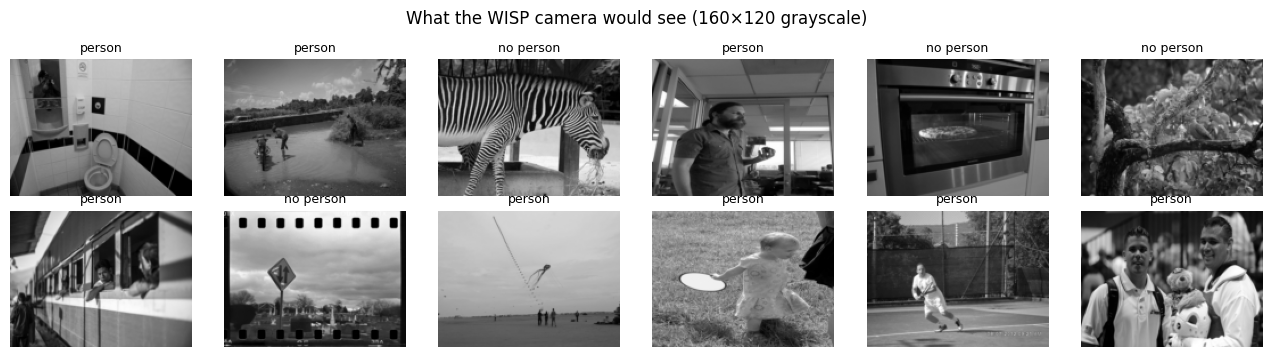

In [ ]:
fig, axes = plt.subplots(2, 6, figsize=(13, 3.6))
for ax, i in zip(axes.flat, np.random.RandomState(1).choice(len(Xtr), 12, replace=False)):
    ax.imshow(Xtr[i], cmap='gray', vmin=0, vmax=255)
    ax.set_title('person' if ytr[i] else 'no person', fontsize=9); ax.axis('off')
plt.suptitle('What the WISP camera would see (160×120 grayscale)'); plt.tight_layout(); plt.show()

In [ ]:
to_t = lambda a: torch.from_numpy(a).to(device)
Xtr_t, ytr_t = to_t(Xtr), to_t(ytr)
Xva_t, yva_t = to_t(Xva), to_t(yva)
Xte_t, yte_t = to_t(Xte), to_t(yte)

def augment(x):
    # x: B,H,W in [0,1]. Random flip, translation (up to ~12% of the frame) and scale,
    # so encoders cannot rely on people appearing in fixed positions; then lighting and sensor noise.
    B, H, W = x.shape
    s = torch.empty(B, device=x.device).uniform_(0.85, 1.15)
    flip = (torch.rand(B, device=x.device) < 0.5).float() * 2 - 1
    theta = torch.zeros(B, 2, 3, device=x.device)
    theta[:, 0, 0] = flip / s
    theta[:, 1, 1] = 1 / s
    theta[:, 0, 2] = torch.empty(B, device=x.device).uniform_(-0.25, 0.25)
    theta[:, 1, 2] = torch.empty(B, device=x.device).uniform_(-0.25, 0.25)
    grid = F.affine_grid(theta, (B, 1, H, W), align_corners=False)
    x = F.grid_sample(x[:, None], grid, padding_mode='border', align_corners=False)[:, 0]
    gain = torch.empty(B, 1, 1, device=x.device).uniform_(0.6, 1.4)
    bias = torch.empty(B, 1, 1, device=x.device).uniform_(-0.1, 0.1)
    return (x * gain + bias + 0.02 * torch.randn_like(x)).clamp(0, 1)

def batches(X, y, bs, shuffle, aug):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        xb = X[j].float() / 255.0
        if aug:
            xb = augment(xb)
        yield xb, y[j].float()

In [ ]:
# Unlabeled COCO frames for pretraining the tag encoders (optional; set CFG['pretrain_extra'] = 0 to skip)
X_extra = None
if CFG['pretrain_extra'] > 0 and not LAB_DIR:
    extra_cache = os.path.join(CACHE_DIR, f"extra_{CFG['pretrain_extra']}_{CFG['img_h']}x{CFG['img_w']}.npz")
    if not os.path.exists(extra_cache):
        if not os.path.exists(ann_zip):
            urllib.request.urlretrieve(ANN_URL, ann_zip)
        with zipfile.ZipFile(ann_zip) as z:
            ann = json.load(z.open('annotations/instances_train2017.json'))
        items = vww_items(ann, CFG['person_area_thresh'])
        del ann; gc.collect()
        # reproduce the labeled training sample exactly, then take frames outside it (test frames come from val2017)
        used = {u for u, _ in balanced_sample(items, CFG['n_train_per_class'], random.Random(CFG['seed']))}
        pool = [it for it in items if it[0] not in used]
        random.Random(CFG['seed'] + 1).shuffle(pool)
        build_split(pool[:CFG['pretrain_extra']], extra_cache)
    X_extra = torch.from_numpy(np.load(extra_cache)['X'])        # kept on the CPU; batches move to the GPU
    if device == 'cuda':
        X_extra = X_extra.pin_memory()
    print(f'unlabeled pretraining frames: {len(X_extra)} (+ {len(Xtr)} labeled training frames)')

extra_60000_120x160.npz:   0%|          | 0/58287 [00:00<?, ?it/s]

saved 58287 images (0 failed downloads) -> /content/drive/MyDrive/wisp_semcom/extra_60000_120x160.npz
unlabeled pretraining frames: 58287 (+ 54000 labeled training frames)


## 3. Models

Everything from v4 is unchanged except the distilled heads. New or changed in v4.1:

| Method | Tag side | Hub side |
|---|---|---|
| `head_distill` | 2×2 binning → ternary 3×3 conv (s2) → ReLU → ternary 3×3 conv (s2) → ReLU → ternary 1×1 → pool → bytes. Ternary weights now carry a per-filter scale (folded into the batch-norm constants on the tag) | neck predicts teacher features → frozen teacher tail. Distills the teacher's pooled embedding (all budgets) and spatial features (≥ 160 B), plus soft labels |
| `head_nodistill` | same | same hub, labels only |
| `head_real_distill` | real-valued weights (multiplies; reference only) | same as `head_distill` |
| `thumbnail_kd` | thumbnail | pretrained MobileNet with lighter soft-label weight |
| `thumb_energy` | thumbnail of (B − E) bytes + E energy values: mean \|response\| of E learned zero-sum ±1 8×8 kernels (stride 8) over the frame | pretrained MobileNet on the thumbnail; energy values pass through a small MLP and join at the final layer |

E grows with the budget: 4 values at 10 B, 8 at 40 B, 16 at 160 B, 32 at 640 B.

In [ ]:
class SignSTE(torch.autograd.Function):
    @staticmethod
    def forward(ctx, w):
        ctx.save_for_backward(w)
        return torch.where(w >= 0, torch.ones_like(w), -torch.ones_like(w))
    @staticmethod
    def backward(ctx, g):
        (w,) = ctx.saved_tensors
        return g * (w.abs() <= 1).to(g.dtype)

def zero_sum_sign(w_lat):
    # Split each pattern at the midpoint of its two middle values: exactly half +1, half -1.
    flat = w_lat.flatten(1)
    s = flat.sort(dim=1).values
    n = s.shape[1]
    mid = (s[:, (n - 1) // 2] + s[:, n // 2]) / 2
    return SignSTE.apply(flat - mid[:, None]).view_as(w_lat)

def ternarize(w):
    # Ternary weights alpha * {-1, 0, +1} per filter (threshold 0.7 * mean|w|; alpha = mean |w| of the kept weights),
    # straight-through gradient. alpha keeps the layer's output scale unchanged at the real -> ternary switch; on the tag
    # it folds into the per-channel batch-norm constants, so the convolution itself is still additions only.
    flat = w.flatten(1)
    delta = 0.7 * flat.abs().mean(1, keepdim=True)
    keep = (flat.abs() > delta).float()
    alpha = (flat.abs() * keep).sum(1, keepdim=True) / keep.sum(1, keepdim=True).clamp(min=1)
    t = alpha * torch.sign(flat) * keep
    return (flat + (t - flat).detach()).view_as(w)

def thumb_size(n_pixels):
    w = max(1, int(math.sqrt(n_pixels * 4 / 3)))
    return max(1, n_pixels // w), w

def ste_round(v):
    return v + (v.round() - v).detach()

class Quantizer(nn.Module):
    def __init__(self, n, bits):
        super().__init__()
        self.bits = bits
        self.offset = nn.Parameter(torch.zeros(n))
        self.log_step = nn.Parameter(torch.zeros(n))
    def _b(self, p, y):
        return p.view(1, -1, *([1] * (y.dim() - 2)))
    def forward(self, y):
        L = 2 ** self.bits
        z = ((y - self._b(self.offset, y)) / self._b(self.log_step.exp(), y) + L / 2).clamp(0, L - 1)
        return ste_round(z)
    @torch.no_grad()
    def calibrate(self, y):
        dims = tuple(d for d in range(y.dim()) if d != 1)
        self.offset.copy_(y.mean(dims))
        self.log_step.copy_(torch.log(8 * y.std(dims) / 2 ** self.bits + 1e-8))

def mobilenet(pretrained):
    return torchvision.models.mobilenet_v3_small(
        weights=torchvision.models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None)

def autocast_on(t):
    return torch.autocast('cuda', dtype=torch.float16, enabled=CFG['use_amp'] and t.is_cuda)

In [ ]:
# ---------------- Receivers ----------------
class ImageReceiver(nn.Module):
    # Image-like payload in [0,1] (C channels + C mask channels) -> 1x1 adapter -> upsample -> MobileNetV3-small.
    # Initialised so channel 0 enters exactly like a grayscale image; other channels start at zero weight.
    def __init__(self, C, pretrained=True):
        super().__init__()
        self.adapter = nn.Conv2d(2 * C, 3, 1)
        with torch.no_grad():
            self.adapter.weight.zero_()
            self.adapter.weight[:, 0] = 1 / 0.225
            self.adapter.bias.fill_(-0.45 / 0.225)
        self.net = mobilenet(pretrained)
        self.net.classifier[3] = nn.Linear(self.net.classifier[3].in_features, 1)
    def embed(self, img, mask):                    # everything up to the final linear layer
        z = self.adapter(torch.cat([img * mask, mask], 1))
        z = F.interpolate(z, size=(CFG['img_h'], CFG['img_w']), mode='bilinear', align_corners=False)
        with autocast_on(z):
            f = self.net.avgpool(self.net.features(z)).flatten(1)
            f = self.net.classifier[:3](f)
        return f.float()
    def forward(self, img, mask):
        return self.net.classifier[3](self.embed(img, mask)).squeeze(1)

class SpatialReceiver(nn.Module):
    def __init__(self, C, pretrained=True):
        super().__init__()
        self.img = ImageReceiver(C, pretrained)
    def forward(self, q, mask):
        return self.img(q / 255.0, mask)

HAAR = torch.tensor([[1., 1., 1., 1.],     # rows: avg, left-right, top-bottom, diagonal
                     [1., -1., 1., -1.],   # columns: quadrants a=top-left, b=top-right, c=bottom-left, d=bottom-right
                     [1., 1., -1., -1.],
                     [1., -1., -1., 1.]])

class HaarReceiver(nn.Module):
    # Dequantize, invert the (learnable, Haar-initialised) 4x4 transform, rearrange each block's 4 values
    # into a 2x2 patch (pixel shuffle) -> a 2x finer image -> the same image receiver as a thumbnail.
    # Missing detail values (progressive prefixes) become 0, i.e. a flat 2x2 patch = the coarse thumbnail.
    def __init__(self, pretrained=True):
        super().__init__()
        self.inv = nn.Conv2d(4, 4, 1, bias=False)
        with torch.no_grad():
            self.inv.weight.copy_(HAAR.t().reshape(4, 4, 1, 1))   # [a,b,c,d] = H^T [avg,dx,dy,dd]
        self.img = ImageReceiver(1, pretrained)
    def forward(self, q, mask):
        v = torch.cat([q[:, :1] / 255.0, (q[:, 1:] - 128) / 255.0], 1) * mask
        img = F.pixel_shuffle(self.inv(v), 2)
        m = F.interpolate(mask[:, :1], scale_factor=2, mode='nearest')
        return self.img(img, m)

class MLPDecoder(nn.Module):
    def __init__(self, n_in, levels, hidden=512, p=0.3):
        super().__init__()
        self.levels = levels
        self.net = nn.Sequential(
            nn.Linear(2 * n_in, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(p),
            nn.Linear(hidden, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(p),
            nn.Linear(hidden, 1))
    def forward(self, q, mask):
        qn = (q / (self.levels - 1)) * 2 - 1
        return self.net(torch.cat([qn * mask, mask], 1)).squeeze(1)

In [ ]:
# ---------------- Tag-side encoders on a grid ----------------
class SpatialEncoder(nn.Module):
    # (from v3) channel 0 = block averages; channels 1..C-1 = 'linear' sub-block patterns or 'energy' kernels
    def __init__(self, budget, C=1, kind='linear', learned=True):
        super().__init__()
        H, W = CFG['img_h'], CFG['img_w']
        self.C, self.kind, self.learned, self.valid, self.quant = C, kind, learned, True, None
        self.grid = thumb_size(max(1, budget // C))
        h, w = self.grid
        self.n_bytes = h * w * C
        if C == 1:
            return
        if kind == 'linear':
            self.p = max(1, min(CFG['local_patch'], H // h, W // w))
            if self.p < 2:
                self.valid = False
                return
            shape = (C - 1, 1, self.p, self.p)
        else:
            self.k = CFG['energy_kernel']
            fits4 = h <= (H - self.k) // 4 + 1 and w <= (W - self.k) // 4 + 1
            self.stride = 4 if fits4 else 2
            shape = (C - 1, 1, self.k, self.k)
        if learned:
            self.W_lat = nn.Parameter(0.3 * torch.randn(shape))
        else:
            n = shape[2] * shape[3]
            base = (torch.arange(n) < n // 2).float() * 2 - 1
            self.register_buffer('W_fixed', base[torch.rand(shape[0], n).argsort(dim=1)].view(shape))
        self.quant = Quantizer(C - 1, CFG['bits'])
    def patterns(self):
        return zero_sum_sign(self.W_lat) if self.learned else self.W_fixed
    def features(self, x):
        h, w = self.grid
        if self.kind == 'linear':
            fine = F.adaptive_avg_pool2d(x[:, None], (h * self.p, w * self.p))
            return F.conv2d(fine, self.patterns(), stride=self.p) / self.p
        r = F.conv2d(x[:, None], self.patterns(), stride=self.stride) / self.k
        return F.adaptive_avg_pool2d(r.abs(), (h, w))
    def forward(self, x):
        q0 = ste_round(F.adaptive_avg_pool2d(x[:, None], self.grid) * 255)
        return q0 if self.C == 1 else torch.cat([q0, self.quant(self.features(x))], 1)
    def post_step(self):
        if self.C > 1 and self.learned:
            with torch.no_grad():
                self.W_lat.clamp_(-1, 1)
    def tag_cost(self):
        H, W = CFG['img_h'], CFG['img_w']
        h, w = self.grid
        adds, bits = H * W, 0
        if self.C > 1 and self.kind == 'linear':
            adds += self.C * (h * self.p) * (w * self.p); bits = (self.C - 1) * self.p ** 2
        elif self.C > 1:
            k, s = self.k, self.stride
            pos = ((H - k) // s + 1) * ((W - k) // s + 1)
            adds += (self.C - 1) * pos * (k * k + 1); bits = (self.C - 1) * k * k
        return dict(adds=adds, weight_bits=bits)

def haar_patterns(p):
    # (3, 1, p, p) detail patterns, each quadrant constant: left-right, top-bottom, diagonal.
    hq = p // 2
    out = torch.zeros(3, 1, p, p)
    for r in range(3):
        a, b, c, d = HAAR[r + 1]
        out[r, 0, :hq, :hq], out[r, 0, :hq, hq:] = a, b
        out[r, 0, hq:, :hq], out[r, 0, hq:, hq:] = c, d
    return out

class HaarEncoder(nn.Module):
    # Tag: block average + 3 detail values from zero-sum +/-1 patterns over a p x p sub-grid, fixed 8-bit
    # quantization (details stored as value*255 + 128). Initialised to Haar: same information as a 2x thumbnail.
    def __init__(self, budget, learned=True):
        super().__init__()
        H, W = CFG['img_h'], CFG['img_w']
        self.C, self.learned, self.valid, self.quant = 4, learned, True, None
        self.grid = thumb_size(max(1, budget // 4))
        h, w = self.grid
        self.p = 4 if (4 * h <= H and 4 * w <= W) else 2
        self.n_bytes = 4 * h * w
        base = haar_patterns(self.p)
        if learned:
            self.W_lat = nn.Parameter(0.5 * base + 0.05 * torch.randn_like(base))
        else:
            self.register_buffer('W_fixed', base)
    def patterns(self):
        return zero_sum_sign(self.W_lat) if self.learned else self.W_fixed
    def forward(self, x):
        h, w = self.grid
        fine = F.adaptive_avg_pool2d(x[:, None], (h * self.p, w * self.p))
        q0 = ste_round(F.avg_pool2d(fine, self.p) * 255)
        det = F.conv2d(fine, self.patterns(), stride=self.p) / self.p ** 2      # in [-0.5, 0.5]
        qd = ste_round((det * 255 + 128).clamp(0, 255))
        return torch.cat([q0, qd], 1)
    def post_step(self):
        if self.learned:
            with torch.no_grad():
                self.W_lat.clamp_(-1, 1)
    def tag_cost(self):
        H, W = CFG['img_h'], CFG['img_w']
        h, w = self.grid
        fine = (h * self.p) * (w * self.p)
        return dict(adds=H * W + 4 * fine, weight_bits=3 * self.p ** 2)

class GridModel(nn.Module):
    # Shared plumbing for payloads laid out on a grid; bytes are sent channel-major (averages first).
    def payload(self, x):
        return self.enc(x)
    def forward(self, x, n_epc=None):
        q = self.payload(x)
        if n_epc is None:
            mask = torch.ones_like(q)
        else:
            idx = torch.arange(q[0].numel(), device=q.device).view(1, *q.shape[1:])
            mask = (idx < (n_epc * CFG['epc_payload_bytes']).view(-1, 1, 1, 1)).float()
        return self.dec(q, mask)
    def post_step(self):
        self.enc.post_step()
    def tag_cost(self):
        return self.enc.tag_cost()

class SpatialModel(GridModel):
    def __init__(self, budget, C=1, kind='linear', learned=True, pretrained=True):
        super().__init__()
        self.enc = SpatialEncoder(budget, C, kind, learned)
        self.dec = SpatialReceiver(C, pretrained)
        self.n_bytes = self.enc.n_bytes
        self.n_epc = math.ceil(self.n_bytes / CFG['epc_payload_bytes'])

class HaarModel(GridModel):
    def __init__(self, budget, learned=True, pretrained=True):
        super().__init__()
        self.enc = HaarEncoder(budget, learned)
        self.dec = HaarReceiver(pretrained)
        self.n_bytes = self.enc.n_bytes
        self.n_epc = math.ceil(self.n_bytes / CFG['epc_payload_bytes'])

class UpperBoundModel(nn.Module):
    # NOT tag-realizable: MobileNetV3 features of the full image -> B bytes -> MLP decoder.
    def __init__(self, budget, pretrained=True):
        super().__init__()
        self.n_bytes, self.n_epc = budget, math.ceil(budget / CFG['epc_payload_bytes'])
        self.features = mobilenet(pretrained).features
        self.proj = nn.Linear(576, budget)
        self.quant = Quantizer(budget, CFG['bits'])
        self.dec = MLPDecoder(budget, 2 ** CFG['bits'])
    def enc_features(self, x):
        x = ((x - 0.45) / 0.225)[:, None].expand(-1, 3, -1, -1)
        with autocast_on(x):
            f = self.features(x)
        return self.proj(F.adaptive_avg_pool2d(f.float(), 1).flatten(1))
    def payload(self, x):
        return self.quant(self.enc_features(x))
    def forward(self, x, n_epc=None):
        q = self.payload(x)
        return self.dec(q, torch.ones_like(q))
    def tag_cost(self):
        return dict(adds=None, weight_bits=None)

In [ ]:
# ---------------- Teacher and distilled tag heads ----------------
class Teacher(nn.Module):
    # Pretrained MobileNetV3-small fine-tuned on full 160x120 grayscale images.
    def __init__(self):
        super().__init__()
        self.net = mobilenet(True)
        self.net.classifier[3] = nn.Linear(self.net.classifier[3].in_features, 1)
        self.n_bytes, self.n_epc = CFG['full_bytes'], math.ceil(CFG['full_bytes'] / CFG['epc_payload_bytes'])
    def _norm(self, x):
        return ((x - 0.45) / 0.225)[:, None].expand(-1, 3, -1, -1)
    def forward(self, x, n_epc=None):
        z = self._norm(x)
        with autocast_on(z):
            out = self.net(z)
        return out.float().squeeze(1)
    @torch.no_grad()
    def cut_and_embed(self, x):                     # spatial features at the cut + pooled embedding (one pass)
        z = self._norm(x)
        with autocast_on(z):
            f_cut = self.net.features[:CFG['teacher_cut']](z)
            emb = self.net.avgpool(self.net.features[CFG['teacher_cut']:](f_cut)).flatten(1)
        return f_cut.float(), emb.float()
    @torch.no_grad()
    def cut(self, x):                               # features at the distillation point
        z = self._norm(x)
        with autocast_on(z):
            f = self.net.features[:CFG['teacher_cut']](z)
        return f.float()
    def tag_cost(self):
        return dict(adds=0, weight_bits=0)

class TagConv(nn.Module):
    # Ternary (or real) conv + batch norm (+ ReLU). Weights named W_lat so they are frozen with the other tag weights.
    def __init__(self, cin, cout, k, stride, ternary=True, relu=True):
        super().__init__()
        self.W_lat = nn.Parameter(torch.randn(cout, cin, k, k) * math.sqrt(2 / (cin * k * k)))
        self.bn = nn.BatchNorm2d(cout)
        self.k, self.stride, self.ternary, self.relu = k, stride, ternary, relu
    def weight(self):
        return ternarize(self.W_lat) if self.ternary else self.W_lat
    def forward(self, x):
        z = self.bn(F.conv2d(x, self.weight(), stride=self.stride, padding=self.k // 2))
        return F.relu(z) if self.relu else z
    def nnz(self):
        with torch.no_grad():
            return int((ternarize(self.W_lat) != 0).sum()) if self.ternary else self.W_lat.numel()

class TagHead(nn.Module):
    # Tag side, additions only (when ternary): 2x2 binning (60x80) -> ternary 3x3 s2 (30x40) -> ReLU
    # -> ternary 3x3 s2 (15x20) -> ReLU -> ternary 1x1 mix -> average-pool to a grid -> 8-bit quantizer.
    def __init__(self, budget, ternary=True):
        super().__init__()
        c1, c2 = CFG['head_channels']
        self.C = min(CFG['head_out'], budget)
        self.grid = thumb_size(max(1, budget // self.C))
        self.n_bytes = self.grid[0] * self.grid[1] * self.C
        self.valid = True
        self.l1 = TagConv(1, c1, 3, 2, ternary)
        self.l2 = TagConv(c1, c2, 3, 2, ternary)
        self.mix = TagConv(c2, self.C, 1, 1, ternary, relu=False)
        self.quant = Quantizer(self.C, CFG['bits'])
    def set_ternary(self, flag):
        for m in (self.l1, self.l2, self.mix):
            m.ternary = flag
    def features(self, x):
        z = F.avg_pool2d(x[:, None], 2)
        return F.adaptive_avg_pool2d(self.mix(self.l2(self.l1(z))), self.grid)
    def forward(self, x):
        return self.quant(self.features(x))
    def post_step(self):
        pass
    def tag_cost(self):
        H, W = CFG['img_h'], CFG['img_w']
        p1, p2 = (H // 4) * (W // 4), (H // 8) * (W // 8)
        c1, c2 = CFG['head_channels']
        adds = (H * W + p1 * self.l1.nnz() + p2 * self.l2.nnz() + p2 * self.mix.nnz()
                + p1 * c1 + p2 * (c2 + self.C) + p2 * self.C)        # + folded BN offsets + pooling
        ternary = self.l1.ternary
        bits = 2 * sum(m.W_lat.numel() for m in (self.l1, self.l2, self.mix)) if ternary else None
        return dict(adds=adds if ternary else None, weight_bits=bits)

class DistillReceiver(nn.Module):
    # Hub: payload -> small conv neck that predicts the teacher's feature map at the cut -> frozen teacher tail.
    def __init__(self, c_in, teacher):
        super().__init__()
        dev = next(teacher.parameters()).device
        Cf, self.Hc, self.Wc = teacher.cut(torch.zeros(1, CFG['img_h'], CFG['img_w'], device=dev)).shape[1:]
        self.inp = nn.Sequential(nn.Conv2d(2 * c_in, 64, 1), nn.BatchNorm2d(64), nn.ReLU())
        self.body = nn.Sequential(
            nn.Conv2d(64, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, Cf, 1))
        self.tail = copy.deepcopy(teacher.net.features[CFG['teacher_cut']:])
        self.cls = copy.deepcopy(teacher.net.classifier)
        for p in list(self.tail.parameters()) + list(self.cls.parameters()):
            p.requires_grad_(False)
    def forward(self, q, mask):
        z = self.inp(torch.cat([(q / 255.0 * 2 - 1) * mask, mask], 1))
        z = F.interpolate(z, size=(self.Hc, self.Wc), mode='bilinear', align_corners=False)
        feat = self.body(z)
        with autocast_on(feat):
            pooled = F.adaptive_avg_pool2d(self.tail(feat), 1).flatten(1)
            out = self.cls(pooled)
        return out.float().squeeze(1), feat, pooled.float()

class DistillModel(nn.Module):
    def __init__(self, budget, teacher, distill=True, ternary=True):
        super().__init__()
        self._teacher = [teacher]                   # kept out of the module tree (not trained, not saved)
        self.enc = TagHead(budget, ternary=False)        # staged: starts real-valued, switches to ternary in on_epoch
        self.final_ternary, self.distill = ternary, distill
        self.dec = DistillReceiver(self.enc.C, teacher)
        self.n_bytes, self.n_epc = self.enc.n_bytes, math.ceil(self.enc.n_bytes / CFG['epc_payload_bytes'])
        self.budget = budget
        self._feat = self._pooled = None
    def train(self, mode=True):
        super().train(mode)
        self.dec.tail.eval(); self.dec.cls.eval()   # frozen teacher tail keeps its batch-norm statistics
        return self
    def on_epoch(self, ep, epochs):
        if self.final_ternary and ep == int(epochs * CFG['ternary_switch_frac']):
            self.enc.set_ternary(True)              # stage 2: real-valued -> ternary
            refresh_bn(self); calibrate(self); refresh_bn(self)
    def selectable(self):                           # don't keep a real-valued checkpoint of a ternary head
        return not (self.final_ternary and not self.enc.l1.ternary)
    def status(self):
        return '  [ternary]' if self.enc.l1.ternary else ''
    def payload(self, x):
        return self.enc(x)
    def forward(self, x, n_epc=None):
        q = self.payload(x)
        out, self._feat, self._pooled = self.dec(q, torch.ones_like(q))
        return out
    def extra_loss(self, x):
        if not self.distill or self._feat is None:
            return 0.0
        t_cut, t_emb = self._teacher[0].cut_and_embed(x)
        loss = F.mse_loss(self._pooled, t_emb) / (t_emb.var() + 1e-6)          # what the teacher concluded
        if self.budget >= CFG['spatial_distill_min_bytes']:                     # spatial detail only if bytes allow
            loss = loss + F.mse_loss(self._feat, t_cut) / (t_cut.var() + 1e-6)
        return CFG['feat_weight'] * loss
    def post_step(self):
        pass
    def tag_cost(self):
        return self.enc.tag_cost()

In [ ]:
# ---------------- Hybrid: thumbnail + nonlinear energy values ----------------
def energy_bytes(budget):
    return max(4, int(round(4 * math.sqrt(budget / 10))))

class HybridEncoder(nn.Module):
    # Tag: a thumbnail of (budget - E) bytes, plus E energy values: for each of E learned zero-sum +/-1 8x8 kernels
    # (stride 8, additions only), the average |response| over the whole frame, 8-bit quantized.
    def __init__(self, budget):
        super().__init__()
        self.E = min(energy_bytes(budget), budget - 1)
        self.grid = thumb_size(max(1, budget - self.E))
        self.n_bytes = self.grid[0] * self.grid[1] + self.E
        self.C, self.valid, self.k = 1, True, CFG['energy_kernel']
        self.W_lat = nn.Parameter(0.3 * torch.randn(self.E, 1, self.k, self.k))
        self.quant = Quantizer(self.E, CFG['bits'])
    def features(self, x):
        r = F.conv2d(x[:, None], zero_sum_sign(self.W_lat), stride=self.k) / self.k
        return r.abs().mean((2, 3))
    def forward(self, x):
        q0 = ste_round(F.adaptive_avg_pool2d(x[:, None], self.grid) * 255)
        return q0, self.quant(self.features(x))
    def post_step(self):
        with torch.no_grad():
            self.W_lat.clamp_(-1, 1)
    def tag_cost(self):
        H, W = CFG['img_h'], CFG['img_w']
        pos = (H // self.k) * (W // self.k)
        return dict(adds=H * W + self.E * pos * (self.k ** 2 + 1), weight_bits=self.E * self.k ** 2)

class HybridReceiver(nn.Module):
    # Thumbnail -> pretrained MobileNet embedding; energy values -> small MLP; both joined at the final layer.
    def __init__(self, E, pretrained=True):
        super().__init__()
        self.img = ImageReceiver(1, pretrained)
        d = self.img.net.classifier[0].out_features
        self.emlp = nn.Sequential(nn.Linear(E, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU())
        self.fc = nn.Linear(d + 128, 1)
    def forward(self, q0, qe):
        emb = self.img.embed(q0 / 255.0, torch.ones_like(q0))
        return self.fc(torch.cat([emb, self.emlp(qe / 255.0 * 2 - 1)], 1)).squeeze(1)

class HybridModel(nn.Module):
    def __init__(self, budget, pretrained=True):
        super().__init__()
        self.enc = HybridEncoder(budget)
        self.dec = HybridReceiver(self.enc.E, pretrained)
        self.n_bytes, self.n_epc = self.enc.n_bytes, math.ceil(self.enc.n_bytes / CFG['epc_payload_bytes'])
    def payload(self, x):
        return self.enc(x)
    def forward(self, x, n_epc=None):
        q0, qe = self.payload(x)
        return self.dec(q0, qe)
    def post_step(self):
        self.enc.post_step()
    def tag_cost(self):
        return self.enc.tag_cost()

## 3b. On-tag FPGA encoders for the iCE40UP5K

**Execution model assumed by the fit check (conservative, layer-sequential):** the frame (optionally 2×2-binned while streaming) is written into SPRAM; each layer reads its input buffer and writes its output buffer in *different* single-port SPRAM blocks. Weights, per-channel requantization constants (int16 multiplier + int32 bias) and a 16-byte layer descriptor are placed smallest-layer-first in EBR (initialised by the bitstream); the rest go to dedicated SPRAM blocks, loaded at power-up from the board's SPI flash. Weights held in SPRAM are re-read once per output row. int8 layers run on the 8 DSP blocks at 70% utilisation; ternary/binary layers on 32 add/subtract lanes in LUTs; requantization uses the DSPs. LUT counts are estimates; replace them with the `yosys synth_ice40` report once RTL exists.

| Method | Tag network | Weights / activations |
|---|---|---|
| v5 `fpga_*_tiny`, `fpga_w8a4_small` | 7-layer depthwise-separable CNN, 160×120 input | as in v5 (results imported) |
| `fpga_w8a8_tiny_long` | v5 tiny, 50 epochs | int8 / uint8 |
| `auto_w8a8`, `auto_w2a8` | largest MobileNetV1-style net that fits, 80×60 binned input, trained from scratch (30 epochs) | int8 or ternary / uint8 |
| `auto_w8a8_pt`, `auto_w2a8_pt` | same networks, pretrained on teacher embeddings, then fine-tuned (15 epochs) | int8 or ternary / uint8 |
| `auto_w2a8_hi_pt` | largest ternary net at the full 160×120 input, pretrained | ternary / uint8 |

First conv and final projection stay 8-bit in ternary networks. Hub side for all: payload → MLP predicting the teacher's pooled embedding → the teacher's frozen classifier, trained with labels + embedding distillation + soft labels.

In [ ]:
# ---------------- iCE40UP5K resource / timing / energy model (pure Python) ----------------
FPGA_ARCHS = {
    'tiny':  [('conv', 1, 8, 3, 2), ('dw', 8, 3, 2), ('pw', 8, 16), ('dw', 16, 3, 2), ('pw', 16, 32),
              ('dw', 32, 3, 2), ('pw', 32, 64)],
    'small': [('conv', 1, 16, 3, 2), ('dw', 16, 3, 2), ('pw', 16, 32), ('dw', 32, 3, 2), ('pw', 32, 64),
              ('dw', 64, 3, 2), ('pw', 64, 128)],
}

def make_div(v, d=4):
    return max(d, int(round(v / d)) * d)

def mbv1_arch(width, n_mid=5):
    # MobileNetV1 layout; the MLPerf Tiny visual-wake-words reference is width 0.25, n_mid 5, at 96x96 RGB
    plan = [(64, 1), (128, 2), (128, 1), (256, 2), (256, 1), (512, 2)] + [(512, 1)] * n_mid + [(1024, 2), (1024, 1)]
    c = make_div(32 * width)
    arch, cin = [('conv', 1, c, 3, 2)], c
    for ch, s in plan:
        c = make_div(ch * width)
        arch += [('dw', cin, 3, s), ('pw', cin, c)]
        cin = c
    return arch

FPGA_METHODS = {   # method -> spec; defaults: distill=True, in_pool=1 (no binning), pretrain=False, epochs=CFG['fpga_epochs']
    'fpga_w8a8_tiny': dict(arch='tiny', w=8, a=8),
    'fpga_w8a8_small': dict(arch='small', w=8, a=8),          # fails the SPRAM check in v5's layout: counter-example
    'fpga_w8a4_small': dict(arch='small', w=8, a=4),
    'fpga_w8a4_tiny': dict(arch='tiny', w=8, a=4),
    'fpga_w2a8_tiny': dict(arch='tiny', w=2, a=8),
    'fpga_w1a8_tiny': dict(arch='tiny', w=1, a=8),
    'fpga_w8a8_tiny_nodistill': dict(arch='tiny', w=8, a=8, distill=False),
    # v5.1
    'fpga_w8a8_tiny_long': dict(arch='tiny', w=8, a=8, epochs=50),
    'auto_w8a8': dict(arch='auto', w=8, a=8, in_pool=2, epochs=30),
    'auto_w2a8': dict(arch='auto', w=2, a=8, in_pool=2, epochs=30),
    'auto_w8a8_pt': dict(arch='auto', w=8, a=8, in_pool=2, pretrain=True),
    'auto_w2a8_pt': dict(arch='auto', w=2, a=8, in_pool=2, pretrain=True),
    'auto_w2a8_hi_pt': dict(arch='auto', w=2, a=8, in_pool=1, pretrain=True),
}

def mspec(method):
    s = {**dict(distill=True, in_pool=1, pretrain=False, epochs=CFG['fpga_epochs']), **FPGA_METHODS[method]}
    if QUICK:
        s['epochs'] = CFG['fpga_epochs']
    return s

def _spec(kind, cin, cout, k, s, g, H, W, Ho, Wo):
    return dict(kind=kind, cin=cin, cout=cout, k=k, s=s, groups=g, Hin=H, Win=W, Hout=Ho, Wout=Wo,
                macs=Ho * Wo * cout * (cin // g) * k * k, params=cout * (cin // g) * k * k,
                in_elems=H * W * cin, out_elems=Ho * Wo * cout)

def head_specs(specs, budget):
    # global average pool + fully connected projection to `budget` bytes, appended to a conv stack
    L = specs[-1]
    H, W, c = L['Hout'], L['Wout'], L['cout']
    pool = dict(kind='pool', cin=c, cout=c, k=1, s=1, groups=c, Hin=H, Win=W, Hout=1, Wout=1,
                macs=H * W * c, params=0, in_elems=H * W * c, out_elems=c)
    return specs + [pool, _spec('fc', c, budget, 1, 1, 1, 1, 1, 1, 1)]

def layer_specs(arch, budget, H=None, W=None):
    H, W = H or CFG['img_h'], W or CFG['img_w']
    out = []
    for L in arch:
        if L[0] == 'conv':
            _, cin, cout, k, s = L; g = 1
        elif L[0] == 'dw':
            _, cin, k, s = L; cout, g = cin, cin
        else:
            _, cin, cout = L; k, s, g = 1, 1, 1
        Ho, Wo = (H + 2 * (k // 2) - k) // s + 1, (W + 2 * (k // 2) - k) // s + 1
        out.append(_spec(L[0], cin, cout, k, s, g, H, W, Ho, Wo))
        H, W = Ho, Wo
    return head_specs(out, budget)

def layer_wbits(i, kind, w_bits):
    # first conv and final projection stay 8-bit in low-bit networks (standard practice; both are small)
    if kind == 'pool':
        return 0
    return 8 if (i == 0 or kind == 'fc') else w_bits

def fpga_fit(specs, w_bits, a_bits, hw=None, in_pool=1):
    hw = hw or FPGA
    blk = hw['spram_bytes'] // 4
    nblk = lambda b: math.ceil(b / blk) if b > 0 else 0
    rows, lanes = [], False
    for i, L in enumerate(specs):
        wb = layer_wbits(i, L['kind'], w_bits)
        dsp_path = wb >= 4 or L['kind'] == 'pool'
        lanes |= not dsp_path
        rows.append(dict(layer=f"{i}:{L['kind']}", shape=f"{L['Hout']}x{L['Wout']}x{L['cout']}", macs=L['macs'],
                         w_bits=wb, w_bytes=L['params'] * wb / 8 + L['cout'] * 6 + hw['descriptor_bytes'],
                         in_bytes=L['in_elems'] * (8 if i == 0 else a_bits) / 8,
                         out_bytes=L['out_elems'] * (8 if L['kind'] == 'fc' else a_bits) / 8,
                         dsp=dsp_path, _L=L))
    # weights + requantization constants + descriptors: smallest layers into EBR, the rest into SPRAM
    ebr_avail = hw['ebr_bytes'] - hw['ebr_reserve_bytes'] - (hw['bin_line_bytes'] if in_pool > 1 else 0)
    used = 0.0
    for r in sorted(rows, key=lambda r: r['w_bytes']):
        r['where'] = 'EBR' if used + r['w_bytes'] <= ebr_avail else 'SPRAM'
        used += r['w_bytes'] if r['where'] == 'EBR' else 0
    spill = sum(r['w_bytes'] for r in rows if r['where'] == 'SPRAM')
    w_blocks = nblk(spill)
    act_blocks = max(nblk(r['in_bytes']) + nblk(r['out_bytes']) for r in rows)   # ping-pong in separate blocks
    cycles = 0.0
    for r in rows:
        L = r['_L']
        units = hw['dsp'] if r['dsp'] else hw['lowbit_lanes']
        compute = L['macs'] / (hw['dsp'] * hw['dsp_eff'] if r['dsp'] else hw['lowbit_lanes'])
        reuse = L['k'] if L['groups'] > 1 else L['k'] * math.ceil(L['cout'] / units)          # input re-reads
        act_mem = max(r['in_bytes'] * reuse / (2 * max(1, nblk(r['in_bytes']))),             # 16 bit per block per cycle
                      r['out_bytes'] / (2 * max(1, nblk(r['out_bytes']))))
        w_mem = r['w_bytes'] * max(1, L['Hout']) / (2 * max(1, w_blocks)) if r['where'] == 'SPRAM' else 0.0
        bound = max((compute, 'compute'), (act_mem, 'activations'), (w_mem, 'weights'))
        r.update(bound=bound[1], cycles=bound[0] + L['out_elems'] / hw['dsp'])                 # + requantization
        cycles += r['cycles']
    luts = hw['luts_fixed'] + (hw['lowbit_lanes'] * hw['luts_per_lane'] if lanes else 0) + \
           (hw['luts_binning'] if in_pool > 1 else 0)
    ms = cycles / (hw['f_mhz'] * 1e3)
    mcu_mW = hw['mcu_uA_per_MHz'] * hw['mcu_f_mhz'] * 1e-3 * hw['mcu_v']
    if hw['weight_store'] == 'flash':        # SPRAM is volatile: weights are re-read from the SPI flash at power-up
        reload_ms = spill * 8 / (hw['flash_mbps'] * 1e3)
        reload_mJ = (hw['p_active_mW'] + hw['flash_mW']) * reload_ms / 1e3
        store_ok = spill <= hw['flash_user_bytes']
    else:                                    # the MSP430 holds them in FRAM and sends them over SPI
        reload_ms = spill * 8 / (hw['spi_mhz'] * 1e3)
        reload_mJ = (mcu_mW + hw['p_static_mW']) * reload_ms / 1e3
        store_ok = spill <= hw['mcu_weight_store_bytes']
    per = hw['reload_per_decision']
    dec_ms = ms + (reload_ms if per else 0)
    mJ = hw['p_active_mW'] * ms / 1e3 + hw['boot_mJ'] + (reload_mJ if per else 0)
    mJ_pess = hw['p_active_mW_pessimistic'] * ms / 1e3 + hw['boot_mJ'] + (reload_mJ if per else 0)
    macs = sum(L['macs'] for L in specs)
    peak_act = max(r['in_bytes'] + r['out_bytes'] for r in rows)
    w_total = sum(L['params'] * r['w_bits'] / 8 for L, r in zip(specs, rows))
    mcu_ms = macs * hw['mcu_cycles_per_mac'] / (hw['mcu_f_mhz'] * 1e3)
    checks = {
        'LUTs': luts <= hw['lut_headroom'] * hw['luts'],
        'SPRAM blocks': act_blocks + w_blocks <= 4,
        'latency': dec_ms <= hw['max_latency_ms'],
        'energy': mJ_pess <= hw['max_energy_mJ'],
        'weight store': store_ok,
    }
    return dict(fits=all(checks.values()), why=', '.join(k for k, v in checks.items() if not v) or 'ok',
                macs=macs, params=sum(L['params'] for L in specs), weight_KB=w_total / 1024,
                ebr_KB=used / 1024, spill_KB=spill / 1024, act_blocks=act_blocks, w_blocks=w_blocks,
                spram_blocks=act_blocks + w_blocks, peak_act_KB=peak_act / 1024, luts=luts, dsp=hw['dsp'],
                cycles=cycles, fpga_ms=ms, fpga_mJ=mJ, fpga_mJ_pess=mJ_pess, reload_ms=reload_ms, reload_mJ=reload_mJ,
                mcu_ms=mcu_ms, mcu_mJ=mcu_mW * mcu_ms / 1e3, mcu_fits=peak_act + w_total <= hw['mcu_buffer_bytes'],
                layers=[{k: v for k, v in r.items() if k != '_L'} for r in rows])

# ---------------- auto-sizing: the largest MobileNetV1-style network that passes every check ----------------
AUTO_WIDTHS = [0.125, 0.1875, 0.25, 0.3125, 0.375, 0.4375, 0.5, 0.625, 0.75]
AUTO_MIDS = [0, 1, 2, 3, 4, 5]
AUTO_SIZE_BUDGET = 40          # networks are sized with a 40-byte projection; larger budgets are re-checked per run
_AUTO, _AUTO_TABLES = {}, {}

def auto_size(w_bits, a_bits, in_pool, budget=AUTO_SIZE_BUDGET, hw=None):
    H, W = CFG['img_h'] // in_pool, CFG['img_w'] // in_pool
    cands, best = [], None
    for wd in AUTO_WIDTHS:
        for m in AUTO_MIDS:
            arch = mbv1_arch(wd, m)
            f = fpga_fit(layer_specs(arch, budget, H, W), w_bits, a_bits, hw, in_pool)
            c = dict(name=f'mbv1_w{wd:g}_m{m}', width=wd, n_mid=m, params_k=f['params'] / 1e3, MACs_M=f['macs'] / 1e6,
                     weights_KB=f['weight_KB'], act_blocks=f['act_blocks'], w_blocks=f['w_blocks'], luts=f['luts'],
                     ms=f['fpga_ms'], mJ_pess=f['fpga_mJ_pess'], reload_ms=f['reload_ms'], fits=f['fits'], why=f['why'])
            cands.append(c)
            if f['fits'] and (best is None or (f['params'], f['macs']) > (best['fit']['params'], best['fit']['macs'])):
                best = dict(name=c['name'], arch=arch, width=wd, n_mid=m, fit=f)
    return best, cands

def resolve_arch(method):
    s = mspec(method)
    if s['arch'] != 'auto':
        return FPGA_ARCHS[s['arch']], s['arch']
    key = (s['w'], s['a'], s['in_pool'])
    if key not in _AUTO:
        _AUTO[key], _AUTO_TABLES[key] = auto_size(*key)
        if _AUTO[key] is None:
            raise RuntimeError(f'no MobileNetV1-style network fits for w{key[0]} a{key[1]} input /{key[2]}')
    return _AUTO[key]['arch'], _AUTO[key]['name']

def method_fit(method, budget):
    s = mspec(method)
    arch, _ = resolve_arch(method)
    H, W = CFG['img_h'] // s['in_pool'], CFG['img_w'] // s['in_pool']
    return fpga_fit(layer_specs(arch, budget, H, W), s['w'], s['a'], in_pool=s['in_pool'])

def module_specs(net, budget):
    # Layer list of any torch conv net (used for the MobileNet upper bound), in the same format as layer_specs.
    specs = []
    def hook(m, inp, out):
        x = inp[0]
        k, s, g = m.kernel_size[0], m.stride[0], m.groups
        kind = 'dw' if g > 1 else ('pw' if k == 1 else 'conv')
        specs.append(_spec(kind, m.in_channels, m.out_channels, k, s, g, x.shape[2], x.shape[3], out.shape[2], out.shape[3]))
    hs = [m.register_forward_hook(hook) for m in net.modules() if isinstance(m, nn.Conv2d)]
    with torch.no_grad():
        net(torch.zeros(1, 3, CFG['img_h'], CFG['img_w']))
    for h in hs:
        h.remove()
    return head_specs(specs, budget)          # the last conv of MobileNetV3-small features is the 576-channel 1x1

def fit_row(name, budget, f):
    return {'method': name, 'budget B': budget, 'FITS': 'yes' if f['fits'] else 'NO', 'fails': '' if f['fits'] else f['why'],
            'params (k)': f['params'] / 1e3, 'MACs (k)': f['macs'] / 1e3, 'weights KB': f['weight_KB'],
            'EBR KB': f['ebr_KB'], 'SPRAM weights KB': f['spill_KB'],
            'SPRAM blocks (act + w) /4': f"{f['act_blocks']} + {f['w_blocks']}", 'LUTs (est)': f['luts'],
            'latency ms': f['fpga_ms'], 'mJ nominal': f['fpga_mJ'], 'mJ pessimistic': f['fpga_mJ_pess'],
            'power-up load ms': f['reload_ms'], 'power-up load mJ': f['reload_mJ'],
            'MSP430 ms': f['mcu_ms'], 'MSP430 mJ': f['mcu_mJ'], 'MSP430 memory ok': f['mcu_fits']}

In [ ]:
# ---------------- Quantization-aware FPGA encoder + hub ----------------
def quant_weight(w, bits):
    # Per-output-channel weight quantization. Returns (fake-quantized weight with straight-through gradient,
    # integer weights, per-channel scale). bits=1: alpha*{-1,+1}; bits=2: alpha*{-1,0,+1}; else symmetric int.
    flat = w.flatten(1)
    if bits == 1:
        alpha = flat.abs().mean(1, keepdim=True)
        q = torch.where(flat >= 0, torch.ones_like(flat), -torch.ones_like(flat))
    elif bits == 2:
        delta = 0.7 * flat.abs().mean(1, keepdim=True)
        keep = (flat.abs() > delta).float()
        alpha = (flat.abs() * keep).sum(1, keepdim=True) / keep.sum(1, keepdim=True).clamp(min=1)
        q = torch.sign(flat) * keep
    else:
        qmax = 2 ** (bits - 1) - 1
        alpha = flat.abs().amax(1, keepdim=True).clamp(min=1e-8) / qmax
        q = (flat / alpha).round().clamp(-qmax, qmax)
    alpha = alpha.clamp(min=1e-8)
    wq = q * alpha
    return (flat + (wq - flat).detach()).view_as(w), q.view_as(w), alpha.flatten()

class ActQuant(nn.Module):
    # Unsigned activation quantizer with a learnable clip (PACT); step = clip / (2^bits - 1), zero point 0.
    def __init__(self, bits, init=4.0):
        super().__init__()
        self.bits = bits
        self.alpha = nn.Parameter(torch.tensor(float(init)))
    def clip(self):
        return self.alpha.abs().clamp(min=1e-3)
    def step(self):
        return self.clip() / (2 ** self.bits - 1)
    def forward(self, z):
        y = torch.minimum(F.relu(z), self.clip())
        s = self.step()
        return ste_round(y / s) * s

class FQLayer(nn.Module):
    # conv (regular / depthwise / pointwise) -> batch norm -> ReLU + activation quantization.
    # On the FPGA the batch norm and the scales fold into one per-channel integer requantization.
    def __init__(self, kind, cin, cout, k, s, groups, w_bits, a_bits):
        super().__init__()
        self.kind, self.cin, self.cout, self.k, self.s, self.groups = kind, cin, cout, k, s, groups
        self.w_bits, self.a_bits, self.quant_w = w_bits, a_bits, True
        fan_in = (cin // groups) * k * k
        self.W_lat = nn.Parameter(torch.randn(cout, cin // groups, k, k) * math.sqrt(2 / fan_in))
        self.bn = nn.BatchNorm2d(cout)
        self.aquant = ActQuant(a_bits)
    def weight(self):
        return quant_weight(self.W_lat, self.w_bits)[0] if self.quant_w else self.W_lat
    def forward(self, a):
        z = self.bn(F.conv2d(a, self.weight(), stride=self.s, padding=self.k // 2, groups=self.groups))
        return self.aquant(z)

class FPGAEncoder(nn.Module):
    def __init__(self, arch, budget, w_bits, a_bits, in_pool=1):
        super().__init__()
        self.w_bits, self.a_bits, self.in_pool = w_bits, a_bits, in_pool
        H, W = CFG['img_h'] // in_pool, CFG['img_w'] // in_pool
        self.specs = layer_specs(arch, budget, H, W)
        self.fit = fpga_fit(self.specs, w_bits, a_bits, in_pool=in_pool)
        self.layers = nn.ModuleList([
            FQLayer(L['kind'], L['cin'], L['cout'], L['k'], L['s'], L['groups'], layer_wbits(i, L['kind'], w_bits), a_bits)
            for i, L in enumerate(self.specs) if L['kind'] not in ('pool', 'fc')])
        c = self.layers[-1].cout
        self.fc_W_lat = nn.Parameter(torch.randn(budget, c) / math.sqrt(c))
        self.fc_b = nn.Parameter(torch.zeros(budget))
        self.quant = Quantizer(budget, CFG['bits'])                 # 8-bit payload, same as every other encoder
        self.n_bytes, self.C, self.valid, self.quant_on = budget, 1, True, True
    def set_quant(self, flag):                                       # staged training for ternary / binary weights
        self.quant_on = flag
        for l in self.layers:
            if l.w_bits <= 2:
                l.quant_w = flag
    def frame(self, x):
        # 8-bit pixels; optional n x n binning done while streaming: (sum + n^2/2) // n^2 on the FPGA
        v = x[:, None] * 255
        if self.in_pool > 1:
            v = F.avg_pool2d(v.round(), self.in_pool)
        return (v + (torch.floor(v + 0.5) - v).detach()) / 255
    def pooled(self, x):
        a = self.frame(x)
        for l in self.layers:
            a = l(a)
        s = self.layers[-1].aquant.step()
        return ste_round(a.mean((2, 3)) / s) * s                     # pooled average stays on the activation grid
    def features(self, x):                                           # real-valued projection before the payload quantizer
        return F.linear(self.pooled(x), quant_weight(self.fc_W_lat, 8)[0], self.fc_b)
    def forward(self, x):
        return self.quant(self.features(x))
    def post_step(self):
        pass
    def tag_cost(self):
        f = self.fit
        return dict(adds=f['macs'], weight_bits=int(round(f['weight_KB'] * 1024 * 8)), params=f['params'],
                    fpga_ms=f['fpga_ms'], fpga_mJ=f['fpga_mJ'], fpga_mJ_pess=f['fpga_mJ_pess'], fpga_luts=f['luts'],
                    spram_blocks=f['spram_blocks'], spill_KB=f['spill_KB'], fpga_fits=f['fits'],
                    reload_ms=f['reload_ms'], reload_mJ=f['reload_mJ'], mcu_ms=f['mcu_ms'], mcu_mJ=f['mcu_mJ'])

class EmbedReceiver(nn.Module):
    # Hub: payload -> MLP predicting the teacher's 576-value pooled embedding -> the teacher's frozen classifier.
    def __init__(self, n_in, teacher, hidden=512):
        super().__init__()
        d = teacher.net.classifier[0].in_features
        self.mlp = nn.Sequential(nn.Linear(n_in, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(0.2),
                                 nn.Linear(hidden, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Linear(hidden, d))
        self.cls = copy.deepcopy(teacher.net.classifier)
        for p in self.cls.parameters():
            p.requires_grad_(False)
    def forward(self, q):
        e = self.mlp(q / 255.0 * 2 - 1)
        return self.cls(e).float().squeeze(1), e

class FPGAModel(nn.Module):
    def __init__(self, budget, method, teacher):
        super().__init__()
        s = mspec(method)
        arch, self.arch_name = resolve_arch(method)
        self._teacher = [teacher]
        self.enc = FPGAEncoder(arch, budget, s['w'], s['a'], s['in_pool'])
        self.dec = EmbedReceiver(budget, teacher)
        self.distill, self.lowbit = s['distill'], s['w'] <= 2
        self.n_bytes, self.n_epc = budget, math.ceil(budget / CFG['epc_payload_bytes'])
        if self.lowbit:
            self.enc.set_quant(False)                                # stage 1: real-valued weights
        self._emb = None
    def train(self, mode=True):
        super().train(mode)
        self.dec.cls.eval()
        return self
    def on_epoch(self, ep, epochs):
        if self.lowbit and ep == int(epochs * CFG['ternary_switch_frac']):
            self.enc.set_quant(True)                                 # stage 2: ternary / binary weights
            refresh_bn(self); calibrate(self); refresh_bn(self)
    def selectable(self):
        return self.enc.quant_on
    def status(self):
        return f'  [w{self.enc.w_bits} quantized]' if self.lowbit and self.enc.quant_on else ''
    def payload(self, x):
        return self.enc(x)
    def forward(self, x, n_epc=None):
        out, self._emb = self.dec(self.payload(x))
        return out
    def extra_loss(self, x):
        if not self.distill or self._emb is None:
            return 0.0
        _, t_emb = self._teacher[0].cut_and_embed(x)
        return CFG['feat_weight'] * F.mse_loss(self._emb, t_emb) / (t_emb.var() + 1e-6)
    def post_step(self):
        pass
    def tag_cost(self):
        return self.enc.tag_cost()

# ---------------- Pretraining: tag network -> teacher's pooled embedding, on labeled + unlabeled frames ----------------
def pretrain_batches(bs):
    n1 = len(Xtr_t)
    n2 = 0 if X_extra is None else len(X_extra)
    perm = torch.randperm(n1 + n2)
    for i in range(0, n1 + n2, bs):
        j = perm[i:i + bs]
        a, b = j[j < n1], j[j >= n1] - n1
        parts = [Xtr_t[a.to(device)]] if len(a) else []
        if len(b):
            parts.append(X_extra[b].to(device, non_blocking=True))
        yield augment(torch.cat(parts).float() / 255.0)

def pretrain_encoder(method, teacher):
    s = mspec(method)
    arch, name = resolve_arch(method)
    path = os.path.join(CACHE_DIR, f"pretrain_{name}_w{s['w']}a{s['a']}p{s['in_pool']}_{tag}.pt")
    if os.path.exists(path):
        print('loaded pretrained encoder', path)
        return torch.load(path, map_location=device)
    torch.manual_seed(0)
    enc = FPGAEncoder(arch, AUTO_SIZE_BUDGET, s['w'], s['a'], s['in_pool']).to(device)
    if s['w'] <= 2:
        enc.set_quant(False)          # pretrain real-valued; the ternary / binary switch happens during fine-tuning
    head = nn.Linear(enc.layers[-1].cout, teacher.net.classifier[0].in_features).to(device)
    params = [p for n, p in enc.named_parameters() if n.startswith('layers.')] + list(head.parameters())
    E = CFG['pretrain_epochs']
    steps = E * math.ceil((len(Xtr_t) + (0 if X_extra is None else len(X_extra))) / CFG['batch_size'])
    opt = torch.optim.AdamW(params, lr=CFG['pretrain_lr'], weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG['pretrain_lr'], total_steps=steps, pct_start=0.1)
    print(f"pretraining {name} (w{s['w']} a{s['a']}, input /{s['in_pool']}) to predict the teacher embedding, {E} epochs")
    t0 = time.time()
    for ep in range(E):
        enc.train(); tot = n = 0
        for xb in pretrain_batches(CFG['batch_size']):
            if len(xb) < 2:
                continue
            _, t_emb = teacher.cut_and_embed(xb)
            loss = F.mse_loss(head(enc.pooled(xb)), t_emb) / (t_emb.var() + 1e-6)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            tot += loss.item() * len(xb); n += len(xb)
        print(f'  ep {ep + 1}/{E}  normalised embedding error {tot / n:.3f}  ({time.time() - t0:.0f}s)')
    state = {k: v.detach().clone() for k, v in enc.state_dict().items() if k.startswith('layers.')}
    torch.save(state, path)
    return state

In [ ]:
# ---------------- Bit-exact integer reference of a trained FPGA encoder + export for the dev board ----------------
# Every stage is: integer accumulate -> add per-channel bias -> arithmetic right shift by r (so the value fits a
# signed 16-bit DSP input) -> multiply by a per-channel int16 multiplier -> round-shift by S -> clamp to [0, L].
# This is what the RTL must implement; its outputs are compared with the float model, and the hub is evaluated on them.

def _requant(acc, M, Bq, L, r=None):
    shape = (1, -1) + (1,) * (acc.dim() - 2)
    Msafe = torch.where(M.abs() > 1e-12, M, torch.full_like(M, 1e-12))
    Bacc = torch.round(Bq / Msafe).to(torch.int64)
    v = acc + Bacc.view(shape)
    if r is None:
        r = max(0, math.ceil(math.log2(v.abs().max().item() + 1)) - 15)
    t = torch.div(v, 2 ** r, rounding_mode='floor')
    Ms = M * 2.0 ** r
    mx = Ms.abs().max().item()
    S = int(math.floor(math.log2((2 ** 15 - 1) / mx))) if mx > 0 else 0
    M_int = torch.round(Ms * 2.0 ** S).to(torch.int64)
    prod = t * M_int.view(shape)
    if S >= 0:
        out = torch.div(prod + (2 ** (S - 1) if S > 0 else 0), 2 ** S, rounding_mode='floor')
    else:
        out = prod * 2 ** (-S)
    return out.clamp(0, L), dict(r=r, S=S, M_int=M_int.tolist(), bias_acc=Bacc.tolist(),
                                 acc_abs_max=v.abs().max().item(), clamp_max=L)

def _bn_fold(bn):
    g = bn.weight.double() / torch.sqrt(bn.running_var.double() + bn.eps)
    return g, bn.bias.double() - bn.running_mean.double() * g

@torch.no_grad()
def int_forward(enc, x_u8, consts=None):
    # x_u8: (N, 120, 160) uint8 frames. consts=None derives the shifts r from this batch (use training frames).
    build = consts is None
    consts = [] if build else consts
    a = x_u8.double()[:, None]
    if enc.in_pool > 1:                                              # streaming binning: (sum + n/2) // n
        n = enc.in_pool ** 2
        a = torch.floor((F.avg_pool2d(a, enc.in_pool) * n + n // 2) / n)
    s_in = 1.0 / 255
    for i, l in enumerate(enc.layers):
        _, q, sw = quant_weight(l.W_lat, l.w_bits)
        acc = F.conv2d(a, q.double(), stride=l.s, padding=l.k // 2, groups=l.groups).round().to(torch.int64)
        g, b = _bn_fold(l.bn)
        s_out = l.aquant.step().double()
        a_int, c = _requant(acc, sw.double() * s_in * g / s_out, b / s_out, 2 ** l.a_bits - 1, None if build else consts[i]['r'])
        if build:
            consts.append(dict(c, stage=f'layer{i}', kind=l.kind, cin=l.cin, cout=l.cout, k=l.k, stride=l.s,
                               groups=l.groups, w_bits=l.w_bits, a_bits=l.a_bits, in_scale=float(s_in), out_scale=s_out.item()))
        a, s_in = a_int.double(), s_out
    n = len(enc.layers)
    HW, C = a.shape[2] * a.shape[3], a.shape[1]
    p_int, c = _requant(a.sum((2, 3)).to(torch.int64), torch.full((C,), 1.0 / HW, dtype=torch.float64, device=a.device),
                        torch.zeros(C, dtype=torch.float64, device=a.device), 2 ** enc.a_bits - 1,
                        None if build else consts[n]['r'])
    if build:
        consts.append(dict(c, stage='pool', kind='pool', n=HW))
    _, q, sw = quant_weight(enc.fc_W_lat, 8)
    acc = (p_int.double() @ q.double().t()).round().to(torch.int64)
    step, off = enc.quant.log_step.exp().double(), enc.quant.offset.double()
    payload, c = _requant(acc, sw.double() * s_in / step, (enc.fc_b.double() - off) / step + 2 ** (CFG['bits'] - 1),
                          2 ** CFG['bits'] - 1, None if build else consts[n + 1]['r'])
    if build:
        consts.append(dict(c, stage='fc', kind='fc', cin=C, cout=payload.shape[1], w_bits=8))
    return payload, consts

def write_export(enc, consts, method, budget, n_vectors=8):
    d = os.path.join(CACHE_DIR, f'fpga_export_{method}_{budget}B')
    os.makedirs(d, exist_ok=True)
    weights = [quant_weight(l.W_lat, l.w_bits)[1] for l in enc.layers] + [quant_weight(enc.fc_W_lat, 8)[1]]
    names = [f'layer{i}' for i in range(len(enc.layers))] + ['fc']
    for name, q in zip(names, weights):
        vals = q.round().to(torch.int64).flatten().cpu().tolist()       # PyTorch order: out, in/groups, kh, kw
        with open(os.path.join(d, f'w_{name}.mem'), 'w') as f:
            f.write('\n'.join(f'{v & 0xFF:02x}' for v in vals))
    with open(os.path.join(d, 'requant.json'), 'w') as f:
        json.dump(dict(device=FPGA['device'], method=method, budget=budget, input_binning=enc.in_pool, stages=consts,
                       fit={k: v for k, v in enc.fit.items() if k != 'layers'}), f, indent=1)
    xs = Xte_t[:n_vectors]
    q_int, _ = int_forward(enc, xs, consts)
    for j in range(n_vectors):
        with open(os.path.join(d, f'vec{j:02d}_in.mem'), 'w') as f:
            f.write('\n'.join(f'{v:02x}' for v in xs[j].flatten().cpu().tolist()))   # row-major 120 x 160, before binning
        with open(os.path.join(d, f'vec{j:02d}_out.mem'), 'w') as f:
            f.write('\n'.join(f'{v:02x}' for v in q_int[j].cpu().tolist()))
    print(f'  exported weights, requantization constants and {n_vectors} test vectors -> {d}')

@torch.no_grad()
def int_check(model, method, budget, export=True, n_calib=512, bs=256):
    model.eval()
    enc = model.enc
    _, consts = int_forward(enc, Xtr_t[:n_calib])
    correct = exact = within1 = total = 0
    maxdiff = 0.0
    for i in range(0, len(Xte_t), bs):
        xu, yb = Xte_t[i:i + bs], yte_t[i:i + bs].float()
        q_int, _ = int_forward(enc, xu, consts)
        diff = (q_int.float() - enc(xu.float() / 255.0)).abs()
        exact += (diff == 0).sum().item(); within1 += (diff <= 1).sum().item(); total += diff.numel()
        maxdiff = max(maxdiff, diff.max().item())
        logit, _ = model.dec(q_int.float())
        correct += ((logit > 0).float() == yb).sum().item()
    rep = dict(int_acc=correct / len(Xte_t), int_exact=exact / total, int_within1=within1 / total, int_maxdiff=maxdiff,
               max_shift_r=max(c['r'] for c in consts))
    print(f"  integer pipeline: test acc {rep['int_acc']:.3f} | payload bytes exact {rep['int_exact']:.1%}, "
          f"within 1 LSB {rep['int_within1']:.1%}, max diff {maxdiff:.0f} | largest pre-shift r = {rep['max_shift_r']}")
    if export:
        write_export(enc, consts, method, budget)
    return rep

In [ ]:
def learned_quant(model):
    if isinstance(model, UpperBoundModel):
        return model.quant, model.enc_features
    enc = getattr(model, 'enc', None)
    if enc is not None and getattr(enc, 'quant', None) is not None:
        return enc.quant, enc.features
    return None, None

@torch.no_grad()
def evaluate(model, fn, X, y, bs=512):
    model.eval()
    correct = 0
    for xb, yb in batches(X, y, bs, shuffle=False, aug=False):
        correct += ((fn(model, xb, False) > 0).float() == yb).sum().item()
    return correct / len(X)

@torch.no_grad()
def calibrate(model, n=2048, bs=256):
    quant, feats = learned_quant(model)
    if quant is None:
        return
    was_training = model.training
    model.eval()
    idx = torch.randperm(len(Xtr_t), device=device)[:n]
    quant.calibrate(torch.cat([feats(augment(Xtr_t[idx[i:i + bs]].float() / 255.0)) for i in range(0, n, bs)]))
    model.train(was_training)

@torch.no_grad()
def saturation(model):
    quant, _ = learned_quant(model)
    if quant is None:
        return float('nan')
    model.eval()
    q = model.payload(Xva_t[:1024].float() / 255.0)
    if isinstance(q, tuple):                        # hybrid: only the energy values are learned-quantized
        q = q[1]
    if isinstance(model, SpatialModel):
        q = q[:, 1:]
    return ((q <= 0) | (q >= 2 ** CFG['bits'] - 1)).float().mean().item()

@torch.no_grad()
def refresh_bn(model, n_batches=None):
    # Re-estimate batch-norm running statistics of the trainable parts (not the frozen teacher tail).
    n_batches = n_batches or CFG['bn_refresh_batches']
    bns = [m for name, m in model.named_modules()
           if isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d)) and not name.startswith(('dec.tail', 'dec.cls'))]
    saved = [(m, m.momentum) for m in bns]
    for m in bns:
        m.reset_running_stats(); m.momentum = None      # cumulative average over the refresh batches
    model.train()
    for i, (xb, _) in enumerate(batches(Xtr_t, ytr_t, CFG['batch_size'], shuffle=True, aug=True)):
        if i >= n_batches:
            break
        model(xb)
    for m, mom in saved:
        m.momentum = mom

def train(model, fn, epochs, name, kd_teacher=None):
    named = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    pat = [p for n, p in named if 'W_lat' in n]
    groups = [dict(params=pat, lr=CFG['lr'] * CFG['enc_lr_mult'], weight_decay=0.0),
              dict(params=[p for n, p in named if 'W_lat' not in n and 'quant.' in n], lr=CFG['lr'], weight_decay=0.0),
              dict(params=[p for n, p in named if 'W_lat' not in n and 'quant.' not in n], lr=CFG['lr'], weight_decay=1e-4)]
    opt = torch.optim.AdamW([g for g in groups if g['params']], lr=CFG['lr'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler('cuda', enabled=CFG['use_amp'] and device == 'cuda')
    freeze_at = epochs - max(1, round(epochs * CFG['freeze_encoder_frac'])) if pat else epochs
    T = CFG['kd_T']
    calibrate(model)
    best_acc, best_state, recal = -1.0, None, False
    t0 = time.time()
    print(name)
    for ep in range(epochs):
        if hasattr(model, 'on_epoch'):
            model.on_epoch(ep, epochs)
        frozen = ep >= freeze_at
        if frozen:
            for p in pat:
                p.requires_grad_(False)
        elif ep < 2 or recal:
            calibrate(model)
        model.train()
        tot, n = 0.0, 0
        for xb, yb in batches(Xtr_t, ytr_t, CFG['batch_size'], shuffle=True, aug=True):
            if len(xb) < 2:
                continue
            logit = fn(model, xb, True)
            loss = F.binary_cross_entropy_with_logits(logit, yb)
            if kd_teacher is not None:
                with torch.no_grad():
                    soft = torch.sigmoid(kd_teacher(xb) / T)
                loss = loss + CFG['kd_weight'] * T * T * F.binary_cross_entropy_with_logits(logit / T, soft)
            if hasattr(model, 'extra_loss'):
                loss = loss + model.extra_loss(xb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if hasattr(model, 'post_step'):
                model.post_step()
            tot += loss.item() * len(xb); n += len(xb)
        sched.step()
        va = evaluate(model, fn, Xva_t, yva_t)
        sat = saturation(model)
        recal = (not frozen) and sat > CFG['recal_if_saturation_above']
        flags = ('  [tag weights frozen]' if frozen and pat else '') + \
                (model.status() if hasattr(model, 'status') else '')
        print(f'  ep {ep + 1}/{epochs}  loss {tot / max(n, 1):.3f}  val {va:.3f}  saturated {sat:.2f}{flags}')
        if va > best_acc and (model.selectable() if hasattr(model, 'selectable') else True):
            best_acc = va
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    if best_state is not None:
        model.load_state_dict(best_state)
    print(f'  -> best val acc {best_acc:.3f}  ({time.time() - t0:.0f}s)')
    return model

plain_fn = lambda m, x, train: m(x)

def prefix_fn(n_eval):
    def fn(m, x, train):
        if train:
            n = torch.randint(1, m.n_epc + 1, (x.shape[0],), device=x.device)
        else:
            n = torch.full((x.shape[0],), n_eval, device=x.device)
        return m(x, n_epc=n)
    return fn

## 4. Results file (imports v5, which already contains v3 to v4.1) and the saved teacher

In [ ]:
res_path = os.path.join(CACHE_DIR, f'results_v51_{tag}.csv')
prev_path = os.path.join(CACHE_DIR, f'results_v5_{tag}.csv')
if IMPORT_PREV and not os.path.exists(res_path) and os.path.exists(prev_path):
    prev = pd.read_csv(prev_path)
    prev.to_csv(res_path, index=False)
    print(f'imported {len(prev)} results from v5')
results = pd.read_csv(res_path).to_dict('records') if os.path.exists(res_path) else []
done = {(r['method'], int(r['budget']), int(r['seed'])) for r in results}
models = {}

def record(method, budget, seed, model, fn, n_bytes=None):
    acc = evaluate(model, fn, Xte_t, yte_t)
    cost = model.tag_cost()
    row = dict(method=method, budget=budget, bytes=n_bytes or model.n_bytes, seed=seed, acc=acc,
               tag_adds=cost['adds'], weight_bits=cost['weight_bits'], source='v5.1',
               train_acc=getattr(model, 'train_acc', np.nan), arch=getattr(model, 'arch_name', None))
    row.update({k: v for k, v in cost.items() if k not in ('adds', 'weight_bits')})   # FPGA fit numbers
    row.update(getattr(model, 'int_report', {}))                                     # integer-pipeline check
    enc = getattr(model, 'enc', None)
    if enc is not None and hasattr(enc, 'grid'):
        row.update(grid=f'{enc.grid[0]}x{enc.grid[1]}', C=getattr(enc, 'C', None))
    results.append(row); done.add((method, budget, seed))
    pd.DataFrame(results).to_csv(res_path, index=False)
    print(f'  TEST acc {acc:.3f}  ({row["bytes"]} bytes)\n')

teacher_path = os.path.join(CACHE_DIR, f'teacher_v4_{tag}.pt')
teacher = Teacher().to(device)
if os.path.exists(teacher_path):
    teacher.load_state_dict(torch.load(teacher_path, map_location=device))
    print('loaded teacher from', teacher_path)
else:
    torch.manual_seed(0)
    teacher = train(teacher, plain_fn, CFG['epochs'], 'teacher: pretrained MobileNetV3 on full images')
    torch.save(teacher.state_dict(), teacher_path)
    record('teacher', CFG['full_bytes'], 0, teacher, plain_fn)
teacher.eval()
for p in teacher.parameters():
    p.requires_grad_(False)
print(f'teacher test acc {evaluate(teacher, plain_fn, Xte_t, yte_t):.3f}')

imported 169 results from v5
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 59.6MB/s]


loaded teacher from /content/drive/MyDrive/wisp_semcom/teacher_v4_30000pc_120x160.pt
teacher test acc 0.833


## 4b. Will it fit? iCE40UP5K check for every FPGA encoder (before any training)

First the auto-sizing search: for each precision / input size used by an `auto_*` method, every MobileNetV1-style candidate (width × number of middle blocks) is checked, and the largest that passes everything is chosen. Then the fit table for every method and budget. Rows marked **NO** are skipped by the training loop (set `CFG['train_unfit'] = True` to train them anyway). The MobileNetV3-small upper bound is included to show why it was labelled not feasible.

"Power-up load" is the one-time cost of reading SPRAM-resident weights from the SPI flash. With `FPGA['reload_per_decision'] = False` (the FPGA stays configured between frames) it is not charged to each decision; set it to `True` to see the power-gated case.

Energy sanity check: Lattice's sensAI human-presence demo (VGG8-like, 16-bit, 64×64×3 input) reports about 7 mW at up to 8 frames/s; the `pessimistic` column uses 7 mW for the whole inference.

In [ ]:
auto_keys = sorted({(mspec(m)['w'], mspec(m)['a'], mspec(m)['in_pool']) for m in FPGA_METHODS if mspec(m)['arch'] == 'auto'})
for key in auto_keys:
    resolve_arch(next(m for m in FPGA_METHODS if mspec(m)['arch'] == 'auto' and (mspec(m)['w'], mspec(m)['a'], mspec(m)['in_pool']) == key))
    cands = pd.DataFrame(_AUTO_TABLES[key])
    chosen = _AUTO[key]
    print(f"w{key[0]} a{key[1]}, input {CFG['img_w'] // key[2]}x{CFG['img_h'] // key[2]}: chosen {chosen['name']} "
          f"({chosen['fit']['params'] / 1e3:.0f}k parameters, {chosen['fit']['macs'] / 1e6:.1f}M MACs)")
    fit_c = cands[cands.fits].sort_values('params_k', ascending=False).head(5)
    miss = cands[~cands.fits].sort_values('params_k').head(5)
    display(pd.concat([fit_c, miss]).round(2))

rows = []
for meth in FPGA_METHODS:
    _, name = resolve_arch(meth)
    for B in FPGA_BUDGETS:
        rows.append(fit_row(f'{meth} [{name}]', B, method_fit(meth, B)))
ub_specs = module_specs(mobilenet(False).features.eval(), 10)
rows.append(fit_row('upper_bound_cnn (MobileNetV3-small, int8)', 10, fpga_fit(ub_specs, 8, 8)))
fit_table = pd.DataFrame(rows)
with pd.option_context('display.float_format', lambda v: f'{v:,.2f}', 'display.max_columns', 30, 'display.width', 250):
    display(fit_table)
fit_table.to_csv(os.path.join(CACHE_DIR, f'v51_fpga_fit_{tag}.csv'), index=False)

print(f"Device: {FPGA['device']}  {FPGA['luts']} LUTs, {FPGA['dsp']} DSPs, {FPGA['spram_bytes'] // 1024} KB SPRAM (4 blocks), "
      f"{FPGA['ebr_bytes'] / 1024:.0f} KB EBR, clock {FPGA['f_mhz']} MHz, weights beyond EBR from {FPGA['weight_store']}")
print('Per-layer breakdown, auto_w2a8_pt @ 10 B:')
display(pd.DataFrame(method_fit('auto_w2a8_pt', 10)['layers']).round(1))

w2 a8, input 160x120: chosen mbv1_w0.125_m5 (60k parameters, 4.4M MACs)


,name,width,n_mid,params_k,MACs_M,weights_KB,act_blocks,w_blocks,luts,ms,mJ_pess,reload_ms,fits,why
5,mbv1_w0.125_m5,0.12,5,59.79,4.40,18.37,3,1,2840,31.24,0.22,4.84,True,ok
4,mbv1_w0.125_m4,0.12,4,55.12,4.03,17.23,3,1,2840,29.64,0.21,4.36,True,ok
3,mbv1_w0.125_m3,0.12,3,50.45,3.65,16.09,3,1,2840,27.99,0.20,3.42,True,ok
2,mbv1_w0.125_m2,0.12,2,45.78,3.28,14.95,3,1,2840,26.39,0.18,3.42,True,ok
1,mbv1_w0.125_m1,0.12,1,41.10,2.90,13.81,3,1,2840,24.79,0.17,3.42,True,ok
6,mbv1_w0.1875_m0,0.19,0,76.14,5.38,24.27,4,1,2840,37.85,0.26,8.03,False,SPRAM blocks
7,mbv1_w0.1875_m1,0.19,1,86.22,6.19,26.73,4,1,2840,40.89,0.29,8.03,False,SPRAM blocks
8,mbv1_w0.1875_m2,0.19,2,96.30,6.99,29.19,4,1,2840,43.93,0.31,9.00,False,SPRAM blocks
9,mbv1_w0.1875_m3,0.19,3,106.38,7.80,31.65,4,2,2840,46.81,0.33,10.93,False,SPRAM blocks
10,mbv1_w0.1875_m4,0.19,4,116.46,8.61,34.11,4,2,2840,49.85,0.35,11.89,False,SPRAM blocks


w2 a8, input 80x60: chosen mbv1_w0.25_m4 (200k parameters, 3.7M MACs)


,name,width,n_mid,params_k,MACs_M,weights_KB,act_blocks,w_blocks,luts,ms,mJ_pess,reload_ms,fits,why
16,mbv1_w0.25_m4,0.25,4,200.16,3.68,56.42,2,2,2990,20.55,0.14,20.89,True,ok
18,mbv1_w0.3125_m0,0.31,0,198.16,3.33,57.81,2,2,2990,20.26,0.14,19.83,True,ok
15,mbv1_w0.25_m3,0.25,3,182.62,3.33,52.14,2,2,2990,19.32,0.14,18.55,True,ok
14,mbv1_w0.25_m2,0.25,2,165.09,2.98,47.86,2,2,2990,18.09,0.13,16.92,True,ok
13,mbv1_w0.25_m1,0.25,1,147.55,2.63,43.58,2,2,2990,16.87,0.12,14.35,True,ok
17,mbv1_w0.25_m5,0.25,5,217.70,4.03,60.70,2,3,2990,21.71,0.15,22.51,False,SPRAM blocks
19,mbv1_w0.3125_m1,0.31,1,225.20,3.87,64.41,2,3,2990,21.98,0.15,23.18,False,SPRAM blocks
20,mbv1_w0.3125_m2,0.31,2,252.24,4.42,71.01,2,3,2990,23.78,0.17,25.64,False,SPRAM blocks
21,mbv1_w0.3125_m3,0.31,3,279.28,4.96,77.61,2,3,2990,25.58,0.18,28.79,False,SPRAM blocks
24,mbv1_w0.375_m0,0.38,0,280.75,4.81,79.87,2,3,2990,26.69,0.19,28.17,False,SPRAM blocks


w8 a8, input 80x60: chosen mbv1_w0.125_m5 (60k parameters, 1.1M MACs)


,name,width,n_mid,params_k,MACs_M,weights_KB,act_blocks,w_blocks,luts,ms,mJ_pess,reload_ms,fits,why
5,mbv1_w0.125_m5,0.12,5,59.79,1.14,58.39,2,2,2350,19.32,0.14,18.82,True,ok
4,mbv1_w0.125_m4,0.12,4,55.12,1.05,53.83,2,2,2350,17.90,0.13,17.32,True,ok
3,mbv1_w0.125_m3,0.12,3,50.45,0.95,49.27,2,2,2350,16.49,0.12,15.00,True,ok
2,mbv1_w0.125_m2,0.12,2,45.78,0.86,44.70,2,2,2350,15.07,0.11,13.50,True,ok
1,mbv1_w0.125_m1,0.12,1,41.10,0.77,40.14,2,2,2350,13.65,0.10,12.01,True,ok
6,mbv1_w0.1875_m0,0.19,0,76.14,1.43,74.36,2,3,2350,24.61,0.17,23.59,False,SPRAM blocks
7,mbv1_w0.1875_m1,0.19,1,86.22,1.63,84.20,2,3,2350,27.65,0.19,27.82,False,SPRAM blocks
8,mbv1_w0.1875_m2,0.19,2,96.30,1.83,94.04,2,3,2350,30.69,0.21,31.09,False,SPRAM blocks
9,mbv1_w0.1875_m3,0.19,3,106.38,2.03,103.89,2,4,2350,33.73,0.24,35.23,False,SPRAM blocks
10,mbv1_w0.1875_m4,0.19,4,116.46,2.24,113.73,2,4,2350,36.77,0.26,38.50,False,SPRAM blocks


,method,budget B,FITS,fails,params (k),MACs (k),weights KB,EBR KB,SPRAM weights KB,SPRAM blocks (act + w) /4,LUTs (est),latency ms,mJ nominal,mJ pessimistic,power-up load ms,power-up load mJ,MSP430 ms,MSP430 mJ,MSP430 memory ok
0,fpga_w8a8_tiny [tiny],10,yes,,3.90,975.04,3.81,5.42,0.00,3 + 0,2200,19.31,0.06,0.14,0.00,0.00,"1,462.56",2.34,False
1,fpga_w8a8_tiny [tiny],40,yes,,5.82,976.96,5.69,7.47,0.00,3 + 0,2200,19.33,0.06,0.14,0.00,0.00,"1,465.44",2.34,False
2,fpga_w8a8_tiny [tiny],160,yes,,13.50,984.64,13.19,4.72,10.95,3 + 1,2200,19.77,0.06,0.14,3.74,0.07,"1,476.96",2.36,False
3,fpga_w8a8_tiny [tiny],640,NO,SPRAM blocks,44.22,"1,015.36",43.19,4.72,43.77,3 + 2,2200,20.24,0.06,0.14,14.94,0.27,"1,523.04",2.44,False
4,fpga_w8a8_small [small],10,NO,SPRAM blocks,13.18,"2,892.16",12.88,7.12,8.77,4 + 1,2200,48.63,0.15,0.34,2.99,0.05,"4,338.24",6.94,False
5,fpga_w8a8_small [small],40,NO,SPRAM blocks,17.02,"2,896.00",16.62,11.05,8.77,4 + 1,2200,48.69,0.15,0.34,2.99,0.05,"4,344.00",6.95,False
6,fpga_w8a8_small [small],160,NO,SPRAM blocks,32.38,"2,911.36",31.62,5.80,29.72,4 + 1,2200,49.51,0.15,0.35,10.14,0.18,"4,367.04",6.99,False
7,fpga_w8a8_small [small],640,NO,SPRAM blocks,93.82,"2,972.80",91.62,5.80,92.53,4 + 3,2200,49.84,0.15,0.35,31.58,0.57,"4,459.20",7.13,False
8,fpga_w8a4_small [small],10,yes,,13.18,"2,892.16",12.88,7.12,8.77,3 + 1,2200,46.59,0.14,0.33,2.99,0.05,"4,338.24",6.94,False
9,fpga_w8a4_small [small],40,yes,,17.02,"2,896.00",16.62,11.05,8.77,3 + 1,2200,46.65,0.14,0.33,2.99,0.05,"4,344.00",6.95,False


Device: iCE40UP5K  5280 LUTs, 8 DSPs, 128 KB SPRAM (4 blocks), 15 KB EBR, clock 12.0 MHz, weights beyond EBR from flash
Per-layer breakdown, auto_w2a8_pt @ 10 B:


,layer,shape,macs,w_bits,w_bytes,in_bytes,out_bytes,dsp,where,bound,cycles
0,0:conv,30x40x8,86400,8,136.0,4800.0,9600.0,True,EBR,compute,16628.6
1,1:dw,30x40x8,86400,2,82.0,9600.0,9600.0,False,EBR,activations,15600.0
2,2:pw,30x40x16,153600,2,144.0,9600.0,19200.0,False,EBR,activations,12000.0
3,3:dw,15x20x16,43200,2,148.0,19200.0,4800.0,False,EBR,activations,29400.0
4,4:pw,15x20x32,153600,2,336.0,4800.0,9600.0,False,EBR,compute,6000.0
5,5:dw,15x20x32,86400,2,280.0,9600.0,9600.0,False,EBR,activations,15600.0
6,6:pw,15x20x32,307200,2,464.0,9600.0,9600.0,False,EBR,compute,10800.0
7,7:dw,8x10x32,23040,2,280.0,9600.0,2560.0,False,EBR,activations,14720.0
8,8:pw,8x10x64,163840,2,912.0,2560.0,5120.0,False,EBR,compute,5760.0
9,9:dw,8x10x64,46080,2,544.0,5120.0,5120.0,False,EBR,activations,8320.0


## 5. Run the experiments

v5.1 FPGA encoders that pass the fit check (Section 4b), with seed 0 at the budgets in `FPGA_PLAN`, then two extra seeds of the key ones at 10 and 40 B. `_pt` methods first pretrain their encoder (once per network, cached in Drive). After each FPGA run, training-set accuracy is measured and the bit-exact integer pipeline is checked and exported for the dev board. Anything already in the results file is skipped; earlier runs are imported, not repeated.

In [ ]:
E, ES, HE, FE = CFG['epochs'], CFG['scratch_epochs'], CFG['head_epochs'], CFG['fpga_epochs']
MAKE = {   # method -> (constructor(budget), epochs, distill from teacher's soft labels?)
    'thumbnail': (lambda B: SpatialModel(B, 1), E, False),
    'upper_bound_cnn': (lambda B: UpperBoundModel(B, True), E, False),
    'haar_learned_C4': (lambda B: HaarModel(B, learned=True), E, False),
    'local_energy_C4': (lambda B: SpatialModel(B, 4, 'energy', True), E, False),
    'thumb_energy': (lambda B: HybridModel(B), E, False),
    'thumbnail_kd': (lambda B: SpatialModel(B, 1), E, True),
    'head_distill': (lambda B: DistillModel(B, teacher, distill=True, ternary=True), HE, True),
    'head_nodistill': (lambda B: DistillModel(B, teacher, distill=False, ternary=True), HE, False),
    'head_real_distill': (lambda B: DistillModel(B, teacher, distill=True, ternary=False), HE, True),
}
for _m in FPGA_METHODS:
    MAKE[_m] = ((lambda B, m=_m: FPGAModel(B, m, teacher)), mspec(_m)['epochs'], mspec(_m)['distill'])

def run(method, budget, seed):
    if (method, budget, seed) in done:
        print(f'skip {method} @ {budget} B, seed {seed} (already done)')
        return None
    make, epochs, kd = MAKE[method]
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    m = make(budget)
    enc = getattr(m, 'enc', None)
    if not getattr(enc, 'valid', True):
        print(f'skip {method} @ {budget} B: blocks too small'); return None
    fit = getattr(enc, 'fit', None)
    if fit is not None and not fit['fits'] and not CFG['train_unfit']:
        print(f"skip {method} @ {budget} B: does not fit on {FPGA['device']} ({fit['why']})"); return None
    if method in FPGA_METHODS and mspec(method)['pretrain']:
        m.enc.load_state_dict(pretrain_encoder(method, teacher), strict=False)
    m = train(m.to(device), plain_fn, epochs, f'{method} @ {budget} B (seed {seed})', kd_teacher=teacher if kd else None)
    if method in FPGA_METHODS:
        m.train_acc = evaluate(m, plain_fn, Xtr_t[:5000], ytr_t[:5000])       # underfitting check (no augmentation)
        print(f'  train acc (no augmentation) {m.train_acc:.3f}')
    if method in FPGA_METHODS and RUN['fpga_int_check']:
        m.int_report = int_check(m, method, budget, export=RUN['fpga_export'] and seed == CFG['seeds'][0])
    record(method, budget, seed, m, plain_fn)
    models[(method, budget, seed)] = m
    return m

# v4.1 experiments (off by default; their results were imported)
for seed in CFG['seeds']:
    for B in CFG['distill_budgets']:
        if RUN['distill']:
            run('head_distill', B, seed); run('head_nodistill', B, seed)
        if RUN['head_real']:
            run('head_real_distill', B, seed)
        if RUN['kd_thumbnail']:
            run('thumbnail_kd', B, seed)
        if RUN['hybrid']:
            run('thumb_energy', B, seed)
if RUN['extra_seeds']:
    for seed in CFG['extra_seeds']:
        for B in CFG['key_budgets']:
            for meth in CFG['key_methods']:
                run(meth, B, seed)

# v5 FPGA encoders (imported)
if RUN['fpga_v5']:
    for meth, budgets in V5_PLAN:
        for B in budgets:
            run(meth, B, CFG['seeds'][0])
# v5.1 FPGA encoders
if RUN['fpga']:
    for meth, budgets in FPGA_PLAN:
        for B in budgets:
            run(meth, B, CFG['seeds'][0])
if RUN['fpga_extra_seeds']:
    for seed in CFG['extra_seeds']:
        for B in CFG['key_budgets']:
            for meth in FPGA_SEED_METHODS:
                run(meth, B, seed)

print(f'{len(results)} results in {res_path}')

fpga_w8a8_tiny_long @ 10 B (seed 0)
  ep 1/50  loss 2.466  val 0.533  saturated 0.87
  ep 2/50  loss 2.389  val 0.574  saturated 0.00
  ep 3/50  loss 2.314  val 0.587  saturated 0.00
  ep 4/50  loss 2.277  val 0.573  saturated 0.00
  ep 5/50  loss 2.248  val 0.609  saturated 0.00
  ep 6/50  loss 2.224  val 0.629  saturated 0.00
  ep 7/50  loss 2.209  val 0.646  saturated 0.00
  ep 8/50  loss 2.194  val 0.632  saturated 0.01
  ep 9/50  loss 2.183  val 0.637  saturated 0.01
  ep 10/50  loss 2.171  val 0.640  saturated 0.00
  ep 11/50  loss 2.158  val 0.644  saturated 0.00
  ep 12/50  loss 2.149  val 0.640  saturated 0.01
  ep 13/50  loss 2.142  val 0.647  saturated 0.01
  ep 14/50  loss 2.136  val 0.658  saturated 0.00
  ep 15/50  loss 2.129  val 0.653  saturated 0.01
  ep 16/50  loss 2.124  val 0.656  saturated 0.01
  ep 17/50  loss 2.115  val 0.656  saturated 0.01
  ep 18/50  loss 2.108  val 0.660  saturated 0.00
  ep 19/50  loss 2.104  val 0.670  saturated 0.00
  ep 20/50  loss 2.099 

## 6. Results

In [ ]:
df_raw = pd.read_csv(res_path)
for c in ['tag_adds', 'weight_bits']:
    df_raw[c] = pd.to_numeric(df_raw[c], errors='coerce')
if 'grid' not in df_raw:
    df_raw['grid'] = np.nan
EXTRA = ['fpga_ms', 'fpga_mJ', 'fpga_mJ_pess', 'fpga_luts', 'spram_blocks', 'mcu_ms', 'mcu_mJ', 'int_acc', 'int_exact',
         'train_acc', 'params', 'reload_ms', 'reload_mJ']
for c in EXTRA:
    df_raw[c] = pd.to_numeric(df_raw[c], errors='coerce') if c in df_raw else np.nan
df = (df_raw.groupby(['method', 'budget'], as_index=False)
      .agg(bytes=('bytes', 'mean'), acc=('acc', 'mean'), acc_std=('acc', 'std'), runs=('acc', 'size'),
           tag_adds=('tag_adds', 'first'), weight_bits=('weight_bits', 'first'), grid=('grid', 'first'), **{c: (c, 'mean') for c in EXTRA}))
df['acc_std'] = df['acc_std'].fillna(0)

def get(method, budget, col='acc'):
    r = df[(df.method == method) & (df.budget == budget)]
    return r[col].iloc[0] if len(r) else np.nan

STYLE = {
    'upper_bound_cnn': ('upper bound: pretrained CNN encoder (not tag-realizable)', 'k^-'),
    'thumbnail': ('thumbnail', 'x-'),
    'thumbnail_kd': ('thumbnail, receiver trained with soft labels', 'x--'),
    'haar_fixed_C4': ('Haar C4 (fixed) + rearranging receiver', 'D-'),
    'haar_learned_C4': ('Haar C4, learned ±1 patterns', 'D--'),
    'head_distill': ('distilled ternary tag head', 'o-'),
    'head_nodistill': ('same head, no distillation', 'o:'),
    'head_real_distill': ('distilled real-valued head (multiplies)', 'o--'),
    'local_linear_C4': ('v3: local ±1 patterns, C4 (stacked channels)', 'v:'),
    'local_energy_C4': ('local filter energies, C4', 's:'),
    'thumb_energy': ('thumbnail + learned energy values (hybrid)', 's-'),
    'v4old_head_distill': ('v4 distilled head (before the ternary fix)', 'o:'),
    'haar_learned_C4_progressive': ('progressive Haar: one model, prefixes', 'P--'),
    'fpga_w8a8_tiny': ('FPGA int8 CNN, tiny (iCE40UP5K)', '*-'),
    'fpga_w8a4_small': ('FPGA small CNN, 4-bit activations', '^-'),
    'fpga_w8a4_tiny': ('FPGA int8 weights / 4-bit activations', '^--'),
    'fpga_w2a8_tiny': ('FPGA ternary-weight CNN', 'v-'),
    'fpga_w1a8_tiny': ('FPGA binary-weight CNN', 'v--'),
    'fpga_w8a8_tiny_nodistill': ('FPGA int8 tiny, no distillation', '*:'),
    'fpga_w8a8_tiny_long': ('FPGA int8 tiny, 50 epochs', '*--'),
    'auto_w8a8': ('FPGA auto-sized int8 net (scratch)', 'D:'),
    'auto_w2a8': ('FPGA auto-sized ternary net (scratch)', 'd:'),
    'auto_w8a8_pt': ('FPGA auto-sized int8 net, pretrained', 'D-'),
    'auto_w2a8_pt': ('FPGA auto-sized ternary net, pretrained', 'd-'),
    'auto_w2a8_hi_pt': ('FPGA auto ternary, 160x120 input, pretrained', 'P-'),
}
def plot_main(xlim=None, fname=None, title=''):
    fig, ax = plt.subplots(figsize=(10, 6))
    for meth, (lab, sty) in STYLE.items():
        g = df[df.method == meth].sort_values('bytes')
        if xlim:
            g = g[(g.bytes >= xlim[0]) & (g.bytes <= xlim[1])]
        if len(g):
            lab2 = lab + (f'  (n={int(g.runs.max())} seeds)' if g.runs.max() > 1 else '')
            ax.errorbar(g.bytes, g.acc * 100, yerr=g.acc_std * 100, fmt=sty, label=lab2, capsize=2, alpha=0.9)
    for meth, ls, lab in [('full_image', '--', 'full image'), ('full_image_scratch', ':', 'full image, scratch receiver')]:
        a = get(meth, CFG['full_bytes'])
        if not np.isnan(a):
            ax.axhline(a * 100, ls=ls, c='gray', label=f'{lab} ({CFG["full_bytes"]:,} B)')
    ax.set_xscale('log'); ax.set_xlabel('bytes actually sent by the tag'); ax.set_ylabel('test accuracy (%)')
    if xlim:
        ax.set_xlim(xlim)
    sec = ax.secondary_xaxis('top', functions=(lambda b: b / CFG['epc_payload_bytes'], lambda e: e * CFG['epc_payload_bytes']))
    sec.set_xlabel('EPCs')
    ax.set_title(title); ax.legend(fontsize=7, loc='lower right'); ax.grid(alpha=0.3)
    plt.tight_layout()
    if fname:
        plt.savefig(os.path.join(CACHE_DIR, fname), dpi=200)
    plt.show()

plot_main(fname=f'v51_accuracy_vs_bytes_{tag}.png', title='Person detection vs. bytes sent (all budgets)')
plot_main(xlim=(6, 800), fname=f'v51_accuracy_small_budgets_{tag}.png', title='Zoom: the small-budget regime (≈ 1–64 EPCs)')

### Same bytes vs. same grid

* **Same bytes:** the encoder against the thumbnail at the same budget. This is the comparison that matters for the thesis.
* **Same grid:** the encoder against a thumbnail with the *same block grid*, i.e. its own average channel alone. This isolates what the extra per-block values add.

For the Haar encoders, the same-bytes thumbnail is also the image-equivalent one (the Haar values carry a 2× finer thumbnail).

In [ ]:
thumbs = df[df.method == 'thumbnail']
rows = []
for meth in ['local_linear_C4', 'local_linear_random_C4', 'local_energy_C4', 'haar_fixed_C4', 'haar_learned_C4']:
    for _, r in df[df.method == meth].sort_values('budget').iterrows():
        sb = get('thumbnail', r.budget)
        sg = thumbs[thumbs.grid == r.grid]
        sg_acc = sg.acc.iloc[0] if len(sg) else np.nan
        rows.append({'method': meth, 'budget': r.budget, 'bytes': r.bytes, 'grid': r.grid, 'acc %': r.acc * 100,
                     'thumbnail same bytes %': sb * 100, 'Δ same bytes': (r.acc - sb) * 100,
                     'thumbnail same grid %': sg_acc * 100, 'Δ same grid': (r.acc - sg_acc) * 100})
display(pd.DataFrame(rows).round(1))

### The small-budget regime (10–640 bytes)

The first table shows mean ± std across seeds (n = number of runs). The second shows the key differences, each with a standard error where at least two runs exist on both sides; a difference larger than about 2 standard errors is unlikely to be noise.

* **distillation effect** = distilled head − same head without distillation
* **ternary cost** = real-valued distilled head − ternary distilled head
* **ternary-fix effect** = v4.1 distilled head − v4 distilled head
* **% of gain captured** = (best cheap encoder − thumbnail) / (upper bound − thumbnail)

In [ ]:
SMALL = ['thumbnail', 'thumbnail_kd', 'haar_learned_C4', 'local_energy_C4', 'thumb_energy',
         'head_nodistill', 'head_distill', 'head_real_distill', 'v4old_head_distill', 'upper_bound_cnn']
def cell(method, B):
    r = df[(df.method == method) & (df.budget == B)]
    if not len(r):
        return ''
    r = r.iloc[0]
    return f'{r.acc * 100:.1f} ± {r.acc_std * 100:.1f} (n={int(r.runs)})' if r.runs > 1 else f'{r.acc * 100:.1f} (n=1)'
tab = pd.DataFrame([{'budget B': B, **{m: cell(m, B) for m in SMALL}} for B in CFG['distill_budgets']])
display(tab)

def diff(a, b, B):
    ra = df[(df.method == a) & (df.budget == B)]
    rb = df[(df.method == b) & (df.budget == B)]
    if not (len(ra) and len(rb)):
        return ''
    ra, rb = ra.iloc[0], rb.iloc[0]
    d = (ra.acc - rb.acc) * 100
    if ra.runs > 1 and rb.runs > 1:
        se = 100 * math.sqrt(ra.acc_std ** 2 / ra.runs + rb.acc_std ** 2 / rb.runs)
        return f'{d:+.1f} ± {se:.1f}'
    return f'{d:+.1f}'

CHEAP_SMALL = ['haar_learned_C4', 'local_energy_C4', 'thumb_energy', 'head_nodistill', 'head_distill', 'thumbnail_kd']
rows = []
for B in CFG['distill_budgets']:
    th, ub = get('thumbnail', B), get('upper_bound_cnn', B)
    cand = df[(df.budget == B) & (df.method.isin(CHEAP_SMALL))]
    best = cand.loc[cand.acc.idxmax()] if len(cand) else None
    rows.append({
        'budget B': B,
        'distillation effect': diff('head_distill', 'head_nodistill', B),
        'ternary cost': diff('head_real_distill', 'head_distill', B),
        'ternary-fix effect': diff('head_distill', 'v4old_head_distill', B),
        'KD on thumbnail': diff('thumbnail_kd', 'thumbnail', B),
        'hybrid vs thumbnail': diff('thumb_energy', 'thumbnail', B),
        'energy C4 vs thumbnail': diff('local_energy_C4', 'thumbnail', B),
        'distilled head vs thumbnail': diff('head_distill', 'thumbnail', B),
        'best cheap encoder': best.method if best is not None else '',
        '% of gain captured': f'{100 * (best.acc - th) / (ub - th):.0f}%' if best is not None and ub - th > 0.005 else '',
    })
display(pd.DataFrame(rows))

In [ ]:
# Gap decomposition over all tag-realizable encoders
CHEAP = ['local_linear_C4', 'local_energy_C4', 'haar_fixed_C4', 'haar_learned_C4', 'thumb_energy', 'head_distill', 'head_nodistill', 'thumbnail_kd']
full = get('full_image', CFG['full_bytes'])
rows = []
for B in sorted(set(CFG['budgets_bytes']) | set(CFG['distill_budgets'])):
    ub, th = get('upper_bound_cnn', B), get('thumbnail', B)
    cand = df[(df.budget == B) & (df.method.isin(CHEAP))]
    best = cand.loc[cand.acc.idxmax()] if len(cand) else None
    b_acc = best.acc if best is not None else np.nan
    gain = ub - th
    rows.append({'budget B': B, 'full image %': full * 100, 'upper bound %': ub * 100, 'thumbnail %': th * 100,
                 'best cheap encoder': best.method if best is not None else '', 'best cheap %': b_acc * 100,
                 'possible gain (pts)': gain * 100, 'captured (pts)': (b_acc - th) * 100,
                 '% of gain captured': 100 * (b_acc - th) / gain if gain > 0.005 else np.nan})
display(pd.DataFrame(rows).round(1))

### v5.1: does a properly sized, pretrained encoder close the gap?

* **train %** is accuracy on 5,000 training frames without augmentation. If it is close to test accuracy, the network is underfitting (too small or undertrained); a large gap means overfitting.
* **% of gap closed** = (encoder − thumbnail) / (upper bound − thumbnail), at the same bytes.
* **integer %** is accuracy when the hub receives the payload from the bit-exact integer pipeline, i.e. what the RTL would produce.
* Differences come with standard errors where both sides have ≥2 seeds (10 and 40 B).

In [ ]:
SHOW = ['thumbnail', 'head_distill', 'fpga_w8a8_tiny', 'fpga_w8a8_tiny_long', 'auto_w8a8', 'auto_w2a8',
        'auto_w8a8_pt', 'auto_w2a8_pt', 'auto_w2a8_hi_pt', 'upper_bound_cnn']
rows = []
for meth in SHOW:
    for B in FPGA_BUDGETS:
        r = df[(df.method == meth) & (df.budget == B)]
        if not len(r):
            continue
        r = r.iloc[0]
        th, ub = get('thumbnail', B), get('upper_bound_cnn', B)
        rows.append({'method': meth, 'budget B': B, 'test %': cell(meth, B), 'train %': r.train_acc * 100,
                     'integer %': r.int_acc * 100, 'params (k)': r.params / 1e3,
                     '% of gap closed': 100 * (r.acc - th) / (ub - th) if ub - th > 0.005 and meth != 'thumbnail' else np.nan,
                     'FPGA ms': r.fpga_ms, 'FPGA mJ (pess.)': r.fpga_mJ_pess, 'power-up load ms': r.reload_ms})
with pd.option_context('display.float_format', lambda v: f'{v:,.1f}', 'display.width', 250):
    display(pd.DataFrame(rows))

rows = []
for B in FPGA_BUDGETS:
    rows.append({
        'budget B': B,
        'long schedule (tiny, 50 vs 15 ep)': diff('fpga_w8a8_tiny_long', 'fpga_w8a8_tiny', B),
        'size (auto w8 vs tiny)': diff('auto_w8a8', 'fpga_w8a8_tiny', B),
        'size (auto w2 vs tiny w2)': diff('auto_w2a8', 'fpga_w2a8_tiny', B),
        'pretraining (w2)': diff('auto_w2a8_pt', 'auto_w2a8', B),
        'pretraining (w8)': diff('auto_w8a8_pt', 'auto_w8a8', B),
        'full-res input (w2, pt)': diff('auto_w2a8_hi_pt', 'auto_w2a8_pt', B),
        'best FPGA vs thumbnail': diff('auto_w2a8_pt', 'thumbnail', B),
        'best FPGA vs MCU head': diff('auto_w2a8_pt', 'head_distill', B),
        'best FPGA vs upper bound': diff('auto_w2a8_pt', 'upper_bound_cnn', B),
    })
display(pd.DataFrame(rows))

# Accuracy vs. network size for the FPGA encoders
fig, ax = plt.subplots(figsize=(8.5, 5))
fp = df[df.method.isin(list(FPGA_METHODS)) & df.params.notna()]
for B, mk in [(10, 'o'), (40, 's')]:
    g = fp[fp.budget == B]
    ax.scatter(g.params, g.acc * 100, marker=mk, label=f'{B} B')
    for _, r in g.iterrows():
        ax.annotate(r.method.replace('fpga_', '').replace('_tiny', ''), (r.params, r.acc * 100), fontsize=6, alpha=0.7)
for meth, ls in [('thumbnail', ':'), ('upper_bound_cnn', '--')]:
    a = get(meth, 10)
    if not np.isnan(a):
        ax.axhline(a * 100, ls=ls, c='gray', label=f'{meth} @ 10 B')
ax.set_xscale('log'); ax.set_xlabel('tag network parameters'); ax.set_ylabel('test accuracy (%)')
ax.set_title('FPGA encoders: accuracy vs. network size'); ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(CACHE_DIR, f'v51_accuracy_vs_params_{tag}.png'), dpi=200); plt.show()

# Accuracy vs. end-to-end tag latency: on-tag compute + backscatter airtime (frame capture excluded; same for all)
t2 = df[df.tag_adds.notna()].copy()
t2['airtime ms'] = np.ceil(t2.bytes / CFG['epc_payload_bytes']) / CFG['epc_per_sec'] * 1000
mcu_compute = t2.tag_adds * CFG['mcu_cycles_per_add'] / (FPGA['mcu_f_mhz'] * 1e3)
t2['compute ms'] = np.where(t2.fpga_ms.notna(), t2.fpga_ms, mcu_compute)
t2['latency ms'] = t2['airtime ms'] + t2['compute ms']
fig, ax = plt.subplots(figsize=(9, 5.5))
for meth, (lab, sty) in STYLE.items():
    g = t2[t2.method == meth]
    if len(g):
        ax.scatter(g['latency ms'], g.acc * 100, marker=next(ch for ch in sty if ch in 'ox^sdDPv*'), label=lab, alpha=0.85)
f = df[df.method == 'full_image']
if len(f):
    lat = math.ceil(CFG['full_bytes'] / CFG['epc_payload_bytes']) / CFG['epc_per_sec'] * 1000
    ax.plot([lat], f.acc * 100, '*', ms=12, c='gray', label='full image')
ax.set_xscale('log'); ax.set_xlabel('tag latency per decision: compute + airtime (ms)'); ax.set_ylabel('test accuracy (%)')
ax.set_title('Accuracy vs. latency (FPGA compute from the fit model; MCU from adds x cycles/add)')
ax.grid(alpha=0.3); ax.legend(fontsize=6.5, loc='lower right'); plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, f'v51_accuracy_vs_latency_{tag}.png'), dpi=200); plt.show()

In [ ]:
# Progressive Haar: each prefix vs. separately trained models of the same size
p = df[df.method == 'haar_learned_C4_progressive'].sort_values('bytes')
if len(p):
    rows = []
    for _, r in p.iterrows():
        rows.append({'prefix bytes': r.bytes, 'progressive %': r.acc * 100})
    out = pd.DataFrame(rows)
    out['contents'] = ['block averages only (coarse thumbnail)', '+ left-right detail', '+ top-bottom detail', 'all (2× thumbnail)'][:len(out)]
    display(out.round(1))
    print(f'reference: thumbnail @160 B = {get("thumbnail", 160) * 100:.1f}%,  thumbnail @640 B = {get("thumbnail", 640) * 100:.1f}%,'
          f'  haar_learned_C4 @640 B = {get("haar_learned_C4", 640) * 100:.1f}%')

### Accuracy vs. tag energy (placeholder constants)

In [ ]:
t = df.copy()
t['EPCs'] = np.ceil(t.bytes / CFG['epc_payload_bytes'])
t['transfer mJ'] = t.EPCs * CFG['energy_per_epc_uJ'] / 1000
t['compute mJ'] = t.tag_adds * CFG['energy_per_add_nJ'] / 1e6
t['compute mJ'] = np.where(t.fpga_mJ.notna(), t.fpga_mJ, t['compute mJ'])   # FPGA rows: modeled iCE40 energy
t['enc+tx mJ'] = t['transfer mJ'] + t['compute mJ']
t['total mJ'] = t['enc+tx mJ'] + CFG['sensing_mJ']
t['airtime ms'] = t.EPCs / CFG['epc_per_sec'] * 1000
t['weights KB'] = t.weight_bits / 8 / 1024
real = t[t.tag_adds.notna() & ~t.method.str.contains('scratch') & ~t.method.isin(['teacher'])]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, col, logx in [(axes[0], 'enc+tx mJ', True), (axes[1], 'total mJ', False)]:
    for meth, (lab, sty) in STYLE.items():
        g = real[real.method == meth]
        if len(g):
            ax.scatter(g[col], g.acc * 100, marker=next(ch for ch in sty if ch in 'ox^sdDPv*'), label=lab, alpha=0.85)
    f = real[real.method == 'full_image']
    if len(f):
        ax.plot(f[col], f.acc * 100, '*', ms=12, c='gray', label='full image')
    front, best = [], -1
    for e, a in real.sort_values(col)[[col, 'acc']].values:
        if a > best:
            front.append((e, a)); best = a
    if front:
        fe, fa = zip(*front); ax.step(fe, np.array(fa) * 100, where='post', c='k', lw=1, alpha=0.6)
    if logx:
        ax.set_xscale('log')
    ax.set_xlabel(f'tag energy per decision: {col}'); ax.set_ylabel('test accuracy (%)'); ax.grid(alpha=0.3)
axes[0].set_title('encoding + transfer'); axes[1].set_title(f'including sensing ({CFG["sensing_mJ"]} mJ)')
axes[0].legend(fontsize=6.5, loc='lower right')
plt.tight_layout(); plt.savefig(os.path.join(CACHE_DIR, f'v51_accuracy_vs_energy_{tag}.png'), dpi=200); plt.show()

cols = ['method', 'budget', 'bytes', 'acc', 'runs', 'EPCs', 'airtime ms', 'transfer mJ', 'compute mJ', 'total mJ', 'weights KB', 'fpga_ms']
pd.set_option('display.float_format', lambda v: f'{v:.3f}')
display(t[cols].sort_values(['method', 'budget']).reset_index(drop=True))

In [ ]:
# Did the learned Haar patterns move away from Haar?
key = ('haar_learned_C4', 640, CFG['seeds'][0])
if key in models:
    enc = models[key].enc
    learned = enc.patterns().detach().cpu()
    base = haar_patterns(enc.p)
    flips = (learned != base).float().mean().item()
    fig, axes = plt.subplots(2, 3, figsize=(6, 4))
    for i in range(3):
        axes[0, i].imshow(base[i, 0], cmap='gray', vmin=-1, vmax=1); axes[0, i].axis('off')
        axes[1, i].imshow(learned[i, 0], cmap='gray', vmin=-1, vmax=1); axes[1, i].axis('off')
    axes[0, 0].set_title('Haar (init)', loc='left', fontsize=9); axes[1, 0].set_title('learned', loc='left', fontsize=9)
    plt.suptitle(f'{flips:.0%} of pattern entries changed sign', fontsize=9); plt.tight_layout(); plt.show()
else:
    print('learned Haar model not in memory this session (patterns are only kept in memory)')

## 7. How to read v5.1

1. **Was v5 underfitting?** Compare *train %* with *test %* for `fpga_w8a8_tiny` and `fpga_w8a8_tiny_long`. Train ≈ test means the network can't fit the data; if the long schedule gains little, the 4 KB network is simply too small.
2. **How big a network fits?** The auto-sizing tables show the largest MobileNetV1-style network per precision, and what stops the next size up (SPRAM blocks, latency, energy). Ternary weights should allow roughly 4× the parameters of int8.
3. **Does size help?** *size (auto vs tiny)* in the difference table. If it is large, capacity was the bottleneck.
4. **Does pretraining help?** *pretraining (w2 / w8)*. The upper bound's main advantage is ImageNet pretraining; this measures how much of that a tag-sized network can absorb from the teacher.
5. **The headline:** *% of gap closed* for `auto_w2a8_pt` at 10 B, with its standard error. High-70s accuracy at 10 B within the fit limits supports the hypothesis that an FPGA tag encoder makes the upper bound realizable; ~65% again means the design rule from v5 stands (compute on the tag below ~40 B; send a thumbnail to a pretrained hub above).
6. **Resolution vs. capacity:** *full-res input* says whether spending SPRAM on a 160×120 input beats spending it on a bigger network at 80×60.
7. **Power-up cost:** if the FPGA is power-gated between frames, the "power-up load" column is paid every decision; check it against the 0.6 mJ budget (or rerun the fit with `reload_per_decision = True`).

**Next steps on the dev board (iCEBreaker / UPduino / UltraPlus breakout all use the same UP5K):** write the layer-sequential engine, check it against the exported test vectors (inputs are full 160×120 frames; binning is part of the RTL), synthesize with `yosys synth_ice40` + `nextpnr-ice40` to replace the LUT estimate, write the SPRAM-resident weights to the flash after the bitstream, and measure current at 12 MHz to replace `p_active_mW` and `flash_mW`.

**Caveats:** auto networks train 30 epochs from scratch versus 20 pretraining + 15 fine-tuning epochs for the `_pt` variants, so the pretraining effect includes extra compute; pretraining for all seeds reuses one seed-0 pretrained encoder; the cycle model assumes a simple layer-sequential engine; LUT, flash and power figures are estimates until measured.